# 03. Evaluasi & Analisis Komparatif Komprehensif (Seluruh Metode Teraudit + `39.02_26.pdf`)
## Baseline (`ONMF-Frobenius`) vs. Pembanding 1 (`ONMF-KL Fixed`) vs. Pembanding 2 (`NMF-HMM-KL`) vs. Pembanding 3 (`IWF`) vs. Metode Baru (`WNNM-RPCA` & `WSNM-RPCA`)

**Mata Kuliah:** Pengolahan Sinyal Digital (PSD)  
**Topik Penelitian:** *Single-Channel Speech Enhancement* via Faktorisasi Matriks, Dinamika Temporal HMM, Pemfilteran Statistik, dan Dekomposisi *Weighted Low-Rank & Sparse* (`39.02_26.pdf`)

---

### 1. Latar Belakang & Ringkasan Penyelarasan Metode
Notebook ini menyatukan evaluasi mendalam terhadap **enam metode** (setelah verifikasi penuh terhadap paper acuan masing-masing di folder `papers/`):
1. **Baseline (`ONMF-Frobenius` — Sack et al., CISS 2022)**: *Online NMF* dengan norma Frobenius dan *sparse coding* $\alpha=100$.
2. **Pembanding 1 (`ONMF-KL Fixed` — Saran Future Work Sack et al., 2022)**: *Online NMF* dengan *Generalized KL Divergence* yang telah **diperbaiki** statistik cukup EM/MM online-nya.
3. **Pembanding 2 (`NMF-HMM-KL` — Xiang et al., EURASIP JASMP 2022)**: Model komposit HMM wicara ($\bar{J}=4, \bar{K}=20$) dan HMM derau ($\ddot{J}=2, \ddot{K}=10$) via *Kronecker product*, pelatihan Baum-Welch EM 30 iterasi, skala STFT float terkalibrasi, dan *MMSE spectral gain* (Eq. 46).
4. **Pembanding 3 (`Implicit Wiener Filter / IWF` — Jaiswal et al., IJST 2022)**: Filter statistik *zero-dictionary* yang telah **diselaraskan** ke parameter paper ($\alpha=0.90$, jendela Hamming 25 ms *overlap* 50%). Pada uji multi-fold, IWF dijalankan secara **kausal *streaming*** mengikuti aliran sinyal (agar inisialisasi 5 frame derau awal tetap valid) lalu hasilnya dipotong per fold untuk evaluasi yang adil.
5. **Metode Baru A (`WNNM-RPCA` — Sridhar & Kumar, `39.02_26.pdf` Algorithm 1)**: Dekomposisi *unsupervised* *Weighted Nuclear Norm Minimization* ($p=1.0$) via ADMM/IALM.
6. **Metode Baru B (`WSNM-RPCA` — Sridhar & Kumar, `39.02_26.pdf` Algorithm 2)**: Generalisasi non-konveks *Weighted Schatten $p$-Norm Minimization* ($p=0.7$) via *Generalized Soft-Thresholding* (GST).

---

### 2. Desain & Protokol Eksperimen Analisis
1. **Evaluasi Multi-Fold (`5-Fold Temporal Cross-Segmentation`)**:
   Sinyal uji wicara (~19,49 detik, `fs = 48.000 Hz`) dipartisi menjadi 5 segmen non-tumpang-tindih (~3,90 detik / ~187.105 sampel per fold).
2. **Pengujian Lintas Kelas Derau**:
   - **White Noise**: Derau stasioner sintetis berspektrum datar (`0–24 kHz`).
   - **Air Noise**: Derau nyata *Levoit-H132 Air Purifier* non-stasioner berspektrum frekuensi rendah (`99,87% <= 4 kHz`).
3. **Uji Signifikansi Statistik Multi-Metode & Inferensial**:
   - **Friedman Test** ($\chi_F^2, p$): Uji omnibus non-parametrik lintas 6 metode pada 5 fold.
   - **Shapiro-Wilk Normality Test** + **Paired Sample $t$-Test** (dengan koreksi *multiple comparison* **Holm-Bonferroni**) + **Cohen's $d$** + **95% Confidence Interval ($\Delta\mu$)** + **Wilcoxon Signed-Rank Test** (catatan: untuk $N=5$ fold, nilai-$p$ minimum teoretis uji Wilcoxon dua arah adalah $2/2^5 = 0{,}0625$).
4. **Analisis Korelasi Pearson ($r$ & $p$)**:
   Mengukur kekuatan hubungan linear antara metrik dekomposisi sinyal (`SDR`, `SIR`, `SAR`), metrik perseptual/inteligibilitas (`PESQ`, `STOI`), deteksi wicara (`VAD F1`), dan efisiensi komputasi (`Latensi`).
5. **Visualisasi Diagnostik**:
   - **VAD Confusion Matrix** untuk keenam metode (*Default* maupun *Tuned*).
   - **Boxplot Skor per Kelas Derau** (`SDR`, `PESQ`, `STOI`) untuk keenam metode, serta komparasi langsung **Sebelum vs Sesudah Tuning Parameter** (`Bagian 4`).
   - **Kurva Validasi Hiperparameter**: Kapasitas kamus $K \in \{10..50\}$ (metode NMF) serta regularisasi $\lambda_{\text{mult}}$ & orde Schatten $p$ (metode `39.02_26.pdf`).
   - **Heatmap & Scatter Korelasi Pearson** ($N=60$ *Default* dan $N=120$ gabungan *Default + Tuned*).
6. **Evaluasi Dual-Track (Bagian 4)**:
   Selain menguji **Track Default Teraudit**, bagian akhir notebook mengevaluasi **Track Parameter-Tuned** (dioptimalkan untuk *Real-World Air Noise* + *Cross-Check White Noise*, termasuk kontrol `Baseline Control (ONMF-Frob 4096)` untuk kesetaraan resolusi STFT) serta menguji signifikansi perubahan sebelum vs sesudah tuning (`Tuned - Default`).


In [1]:
import sys
import os
import time
import warnings
import numpy as np
import scipy
import scipy.io.wavfile as wavfile
import scipy.signal as signal
import scipy.stats as stats
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

possible_roots = [
    os.path.abspath("Audio-Enhancement-via-ONMF"),
    os.path.abspath("."),
    os.path.abspath(".."),
    os.path.abspath("../Audio-Enhancement-via-ONMF"),
    r"D:\College\Research\PSD\Audio-Enhancement-via-ONMF",
]
repo_root = next((p for p in possible_roots if os.path.exists(os.path.join(p, "onmf.py"))), None)
if repo_root is None:
    raise FileNotFoundError("Direktori basis Audio-Enhancement-via-ONMF tidak ditemukan!")

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

figures_dir = os.path.join(repo_root, "pembanding")
os.makedirs(figures_dir, exist_ok=True)

from onmf import Online_NMF
from performance import measures, select_perm
import pesq
import pystoi

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
warnings.filterwarnings('ignore')

print("Lingkungan eksekusi 03_hasil_analisis berhasil dikonfigurasi:")
print(f"- NumPy / SciPy / Pandas : {np.__version__} / {scipy.__version__} / {pd.__version__}")
print(f"- Repository Root        : {repo_root}")
print(f"- Direktori Artefak      : {figures_dir}")

Lingkungan eksekusi 03_hasil_analisis berhasil dikonfigurasi:
- NumPy / SciPy / Pandas : 2.2.5 / 1.15.3 / 2.3.3
- Repository Root        : d:\College\Research\PSD\Audio-Enhancement-via-ONMF
- Direktori Artefak      : d:\College\Research\PSD\Audio-Enhancement-via-ONMF\pembanding


In [2]:
def calculate_full_metrics(enh_voice, enh_noise, orig_voice, orig_noise, fs=48000):
    """Menghitung SDR, SIR, SAR (BSS Eval), PESQ WB (16 kHz), dan STOI secara akurat."""
    L = min(len(enh_voice), len(enh_noise), len(orig_voice), len(orig_noise))
    s_enh = enh_voice[:L].astype(float)
    n_enh = enh_noise[:L].astype(float)
    s_ref = orig_voice[:L].astype(float)
    n_ref = orig_noise[:L].astype(float)

    synth = np.vstack([s_enh, n_enh])
    orig = np.vstack([s_ref, n_ref])
    _, perf = select_perm(*measures(synth, orig))
    sdr, sir, sar = perf[0, 0], perf[1, 0], perf[2, 0]

    down_factor = int(round(fs / 100))
    s_ref_16k = signal.resample_poly(s_ref, 160, down_factor)
    s_enh_16k = signal.resample_poly(s_enh, 160, down_factor)

    s_ref_16k = s_ref_16k / (np.max(np.abs(s_ref_16k)) + 1e-8) * 0.95
    s_enh_16k = s_enh_16k / (np.max(np.abs(s_enh_16k)) + 1e-8) * 0.95

    try:
        pesq_wb = pesq.pesq(16000, s_ref_16k, s_enh_16k, 'wb')
    except Exception:
        pesq_wb = np.nan

    try:
        stoi_score = pystoi.stoi(s_ref_16k, s_enh_16k, 16000, extended=False)
    except Exception:
        stoi_score = np.nan

    return {
        "SDR": float(sdr),
        "SIR": float(sir),
        "SAR": float(sar),
        "PESQ": float(pesq_wb),
        "STOI": float(stoi_score),
    }

print("Modul metrik terpadu siap (fs=48000 Hz -> 16000 Hz eksak).")

Modul metrik terpadu siap (fs=48000 Hz -> 16000 Hz eksak).


In [3]:
# 1. Baseline: ONMF + Frobenius (Sack et al. 2022)
def update_code_within_radius_safe(X, W, H0=None, r=None, alpha=0, sub_iter=100, stopping_diff=0.01):
    A = W.T @ W
    B = W.T @ X
    if H0 is None:
        H0 = np.random.rand(W.shape[1], X.shape[1])
    H1 = H0.copy()
    i, dist = 0, 1.0
    while (i < sub_iter) and (dist > stopping_diff):
        H1_old = H1.copy()
        for k in range(H1.shape[0]):
            grad = np.dot(A[k, :], H1) - B[k, :] + alpha * np.ones(H1.shape[1])
            H1[k, :] = np.maximum(H1[k, :] - (1.0 / (((i + 10) ** 0.5) * (A[k, k] + 1.0))) * grad, 0.0)
            if r is not None:
                d = np.linalg.norm(H1 - H0, 2)
                H1 = H0 + (r / max(r, d)) * (H1 - H0)
            H0 = H1
        dist = np.linalg.norm(H1 - H1_old, 2) / (np.linalg.norm(H1_old, 2) + 1e-12)
        i += 1
    return H1


class Baseline_ONMF_Frobenius:
    def __init__(self, n_components=[50, 10], iterations=100, sub_iter=5, batch_size=50, num_patches=100, alpha=100,
                 nperseg=2048, noverlap=1024):
        self.n_components = n_components
        self.iterations = iterations
        self.sub_iter = sub_iter
        self.batch_size = batch_size
        self.num_patches = num_patches
        self.alpha = alpha
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.Ws, self.Wn = None, None

    def train_dictionary(self, spec, n_comp):
        F, N = spec.shape
        W = np.abs(np.random.rand(F, n_comp))
        At, Bt = None, None
        for t in range(self.iterations):
            idx = np.random.choice(N, size=self.num_patches, replace=True)
            Xt = spec[:, idx]
            if t == 0:
                nmf = Online_NMF(Xt, n_components=n_comp, iterations=self.sub_iter, batch_size=self.batch_size)
            else:
                nmf = Online_NMF(Xt, n_components=n_comp, iterations=self.sub_iter, batch_size=self.batch_size,
                                 ini_dict=W, ini_A=At, ini_B=Bt, history=nmf.history)
            W, At, Bt, _ = nmf.train_dict()
        return W

    def fit_dictionaries(self, train_speech_spec, train_noise_spec):
        t0 = time.time()
        self.Ws = self.train_dictionary(train_speech_spec, self.n_components[0])
        self.Wn = self.train_dictionary(train_noise_spec, self.n_components[1])
        return time.time() - t0

    def separate_fold(self, mix_stft, fs=48000):
        t0 = time.time()
        Y = np.abs(mix_stft)
        W_comb = np.concatenate([self.Ws, self.Wn], axis=1)
        F, N = Y.shape
        sep_s = np.zeros_like(Y)
        sep_n = np.zeros_like(Y)
        D_s = np.concatenate([self.Ws, np.zeros_like(self.Wn)], axis=1)
        D_n = np.concatenate([np.zeros_like(self.Ws), self.Wn], axis=1)
        for i in range(N):
            code = update_code_within_radius_safe(Y[:, i:i+1], W_comb, alpha=self.alpha, sub_iter=100, stopping_diff=0.01)
            sep_s[:, i] = np.dot(D_s, code).ravel()
            sep_n[:, i] = np.dot(D_n, code).ravel()
        denom = sep_s + sep_n + 1e-12
        v_audio = signal.istft(mix_stft * (sep_s / denom), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(mix_stft * (sep_n / denom), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        return v_audio, n_audio, time.time() - t0


# 2. Pembanding 1: ONMF + KL Divergence (Fixed & Tunable)
class Pembanding1_ONMF_KL:
    def __init__(self, n_components=[50, 10], iterations=100, sub_iter=10, num_patches=100, sep_iter=50, beta=0.7,
                 alpha_s=0.0, wiener_q=1.0, nperseg=2048, noverlap=1024):
        self.n_components = n_components
        self.iterations = iterations
        self.sub_iter = sub_iter
        self.num_patches = num_patches
        self.sep_iter = sep_iter
        self.beta = beta
        self.alpha_s = alpha_s
        self.wiener_q = wiener_q
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.Ws, self.Wn = None, None

    def train_dictionary(self, spec, n_comp):
        F, N = spec.shape
        K = n_comp
        W = np.abs(np.random.rand(F, K)) + 0.1
        W /= (np.sum(W, axis=0, keepdims=True) + 1e-12)
        A = np.zeros((F, K))
        B = np.zeros((F, K))
        for t in range(1, self.iterations + 1):
            idx = np.random.choice(N, size=self.num_patches, replace=True)
            Xt = spec[:, idx]
            H = np.abs(np.random.rand(K, self.num_patches)) + 0.1
            W_sum_T = np.sum(W, axis=0, keepdims=True).T
            for _ in range(self.sub_iter):
                WH = W @ H + 1e-10
                H *= (W.T @ (Xt / WH)) / (W_sum_T @ np.ones((1, self.num_patches)) + 1e-10)
            WH = W @ H + 1e-10
            gamma_t = (t + 10) ** (-self.beta)
            A = (1.0 - gamma_t) * A + gamma_t * (W * ((Xt / WH) @ H.T))
            B = (1.0 - gamma_t) * B + gamma_t * (np.ones_like(Xt) @ H.T)
            W = A / (B + 1e-10)
            W /= (np.sum(W, axis=0, keepdims=True) + 1e-12)
        return W

    def fit_dictionaries(self, train_speech_spec, train_noise_spec):
        t0 = time.time()
        self.Ws = self.train_dictionary(train_speech_spec, self.n_components[0])
        self.Wn = self.train_dictionary(train_noise_spec, self.n_components[1])
        return time.time() - t0

    def separate_fold(self, mix_stft, fs=48000):
        t0 = time.time()
        Y = np.abs(mix_stft)
        Ks, Kn = self.n_components[0], self.n_components[1]
        W_comb = np.hstack([self.Ws, self.Wn])
        H_comb = np.abs(np.random.rand(W_comb.shape[1], Y.shape[1])) + 0.1
        reg_vec = np.vstack([np.full((Ks, 1), self.alpha_s), np.zeros((Kn, 1))])
        den_const = (np.sum(W_comb, axis=0, keepdims=True).T + reg_vec) @ np.ones((1, Y.shape[1])) + 1e-10
        for _ in range(self.sep_iter):
            WH = W_comb @ H_comb + 1e-10
            H_comb *= (W_comb.T @ (Y / WH)) / den_const
        S_est = self.Ws @ H_comb[:Ks, :]
        N_est = self.Wn @ H_comb[Ks:, :]
        if self.wiener_q != 1.0:
            S_q, N_q = np.power(S_est, self.wiener_q), np.power(N_est, self.wiener_q)
        else:
            S_q, N_q = S_est, N_est
        tot = S_q + N_q + 1e-12
        v_audio = signal.istft(mix_stft * (S_q / tot), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(mix_stft * (N_q / tot), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        return v_audio, n_audio, time.time() - t0


# 3. Pembanding 2: NMF + HMM + KL (Xiang et al. 2022, Aligned & Tunable)
class Pembanding2_NMF_HMM_KL:
    def __init__(self, n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10,
                 em_iters=30, inner_mu=1, online_iters=15, stft_scale=1.0/32.0,
                 alpha_s=0.0, gain_pow=1.0, nperseg=2048, noverlap=1024):
        self.Js = n_states
        self.Ks = k_speech_per_state
        self.Jn = n_noise_states
        self.Kn = k_noise_per_state
        self.em_iters = em_iters
        self.inner_mu = inner_mu
        self.online_iters = online_iters
        self.stft_scale = stft_scale
        self.alpha_s = alpha_s
        self.gain_pow = gain_pow
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.W_s, self.A_s, self.pi_s = [], None, None
        self.W_n, self.A_n, self.pi_n = [], None, None

    def _train_hmm(self, Spec, J, K):
        F, N = Spec.shape
        W_states = [np.abs(np.random.rand(F, K)) + 0.1 for _ in range(J)]
        H_states = [np.abs(np.random.rand(K, N)) + 0.1 for _ in range(J)]
        for j in range(J):
            W_states[j] /= (np.sum(W_states[j], axis=0, keepdims=True) + 1e-12)
        A = np.ones((J, J)) / J if J == 1 else (np.eye(J) * 0.7 + (1.0 - np.eye(J)) * (0.3 / (J - 1)))
        pi = np.ones(J) / J
        ones_F = np.ones((F, 1))
        ones_N = np.ones((1, N))

        for _ in range(self.em_iters):
            if J > 1:
                log_em = np.zeros((J, N))
                for j in range(J):
                    WH = W_states[j] @ H_states[j] + 1e-10
                    log_em[j] = np.sum(Spec * np.log(WH) - WH, axis=0)
                P_em = np.exp(log_em - np.max(log_em, axis=0, keepdims=True))
                alpha = np.zeros((J, N)); c = np.zeros(N)
                alpha[:, 0] = pi * P_em[:, 0]
                c[0] = 1.0 / (np.sum(alpha[:, 0]) + 1e-12)
                alpha[:, 0] *= c[0]
                for n in range(1, N):
                    alpha[:, n] = (alpha[:, n - 1] @ A) * P_em[:, n]
                    c[n] = 1.0 / (np.sum(alpha[:, n]) + 1e-12)
                    alpha[:, n] *= c[n]
                beta = np.zeros((J, N)); beta[:, -1] = c[-1]
                for n in range(N - 2, -1, -1):
                    beta[:, n] = (A @ (P_em[:, n + 1] * beta[:, n + 1])) * c[n]
                gamma = alpha * beta
                gamma /= (np.sum(gamma, axis=0, keepdims=True) + 1e-12)
                A_num = A * (alpha[:, :-1] @ (P_em[:, 1:] * beta[:, 1:]).T)
                A = A_num / (np.sum(A_num, axis=1, keepdims=True) + 1e-12)
                pi = gamma[:, 0]
            else:
                gamma = np.ones((1, N))

            for j in range(J):
                Wj, Hj, Lj = W_states[j], H_states[j], gamma[j, :]
                for _ in range(self.inner_mu):
                    WH = Wj @ Hj + 1e-10
                    HL = Hj * Lj
                    Wj *= ((Spec / WH) @ HL.T + 1e-12) / (ones_F @ np.sum(HL, axis=1, keepdims=True).T + 1e-12)
                    Wj /= (np.sum(Wj, axis=0, keepdims=True) + 1e-12)
                    WH = Wj @ Hj + 1e-10
                    sum_W = np.sum(Wj, axis=0, keepdims=True).T
                    Hj *= (Wj.T @ (Spec / WH) + 1e-12) / (sum_W @ ones_N + 1e-12)
                W_states[j], H_states[j] = Wj, Hj
        return W_states, A, pi

    def fit_dictionaries(self, Ss, Sn):
        t0 = time.time()
        self.W_s, self.A_s, self.pi_s = self._train_hmm(Ss * self.stft_scale, self.Js, self.Ks)
        self.W_n, self.A_n, self.pi_n = self._train_hmm(Sn * self.stft_scale, self.Jn, self.Kn)
        return time.time() - t0

    def separate_fold(self, mix_stft, fs=48000):
        t0 = time.time()
        Y = np.abs(mix_stft) * self.stft_scale
        F, N = Y.shape
        M = self.Js * self.Jn
        pi_comp = np.kron(self.pi_s, self.pi_n)
        A_comp = np.kron(self.A_s, self.A_n)

        p_all = np.zeros((M, F, N))
        log_lik = np.zeros((M, N))
        ones_N = np.ones((1, N))
        reg_vec = np.vstack([np.full((self.Ks, 1), self.alpha_s), np.zeros((self.Kn, 1))])

        idx = 0
        for j in range(self.Js):
            for k in range(self.Jn):
                W_comb = np.hstack([self.W_s[j], self.W_n[k]])
                H_comb = np.abs(np.random.rand(self.Ks + self.Kn, N)) + 0.1
                den_const = (np.sum(W_comb, axis=0, keepdims=True).T + reg_vec) @ ones_N + 1e-12
                for _ in range(self.online_iters):
                    WH = W_comb @ H_comb + 1e-10
                    H_comb *= (W_comb.T @ (Y / WH)) / den_const
                Sj = self.W_s[j] @ H_comb[:self.Ks, :]
                Nk = self.W_n[k] @ H_comb[self.Ks:, :]
                lam = Sj + Nk + 1e-10
                p_all[idx] = Sj / lam
                log_lik[idx] = np.sum(Y * np.log(lam) - lam, axis=0)
                idx += 1

        omega = np.zeros((M, N))
        mu = pi_comp.copy()
        for n in range(N):
            lik = np.exp(log_lik[:, n] - np.max(log_lik[:, n]))
            w_un = lik * (mu + 1e-12)
            omega[:, n] = w_un / (np.sum(w_un) + 1e-12)
            mu = omega[:, n] @ A_comp

        gs = np.sum(omega[:, np.newaxis, :] * p_all, axis=0)
        if self.gain_pow != 1.0:
            gs = np.power(np.clip(gs, 0.0, 1.0), self.gain_pow)
        gn = 1.0 - gs
        v_audio = signal.istft(mix_stft * gs, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(mix_stft * gn, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        return v_audio, n_audio, time.time() - t0


# 4. Pembanding 3: Implicit Wiener Filter (Jaiswal et al. 2022, Aligned & Tunable)
class Pembanding3_ImplicitWienerFilter:
    def __init__(self, alpha=0.90, frame_ms=25.0, beta_floor=0.01, n_initial_noise_frames=5,
                 vad_snr_thresh=3.0, beta_wiener=0.5):
        self.alpha = alpha
        self.frame_ms = frame_ms
        self.beta_floor = beta_floor
        self.n_init_frames = n_initial_noise_frames
        self.vad_snr_thresh = vad_snr_thresh
        self.beta_wiener = beta_wiener

    def enhance(self, mix_audio, fs=48000):
        t0 = time.time()
        mix = mix_audio[:, 0] if mix_audio.ndim > 1 else mix_audio
        nperseg = int(round(self.frame_ms * 1e-3 * fs))
        noverlap = nperseg // 2
        _, _, Zxx = signal.stft(mix.astype(float), fs=fs, window='hamming',
                                nperseg=nperseg, noverlap=noverlap, boundary=None)
        Pyy = np.abs(Zxx) ** 2
        _, N = Pyy.shape
        Pdd = np.mean(Pyy[:, :min(self.n_init_frames, N)], axis=1, keepdims=True)
        S_hat = np.zeros_like(Pyy)
        for k in range(N):
            Pc = Pyy[:, k:k+1]
            snr_f = 10.0 * np.log10(np.maximum(np.sum(Pc) / (np.sum(Pdd) + 1e-12), 1e-4))
            gamma = np.clip(4.0 - 0.15 * snr_f, 1.0, 5.0)
            if snr_f < self.vad_snr_thresh:
                Pdd = self.alpha * Pdd + (1.0 - self.alpha) * Pc
            ratio = np.maximum((Pc - gamma * Pdd) / (Pc + 1e-12), self.beta_floor)
            S_hat[:, k:k+1] = np.power(ratio, self.beta_wiener) * np.sqrt(Pc)
        _, enh = signal.istft(S_hat * np.exp(1j * np.angle(Zxx)), fs=fs, window='hamming',
                              nperseg=nperseg, noverlap=noverlap, boundary=None)
        L = min(len(mix), len(enh))
        return enh[:L], mix[:L].astype(float) - enh[:L], time.time() - t0


# 5 & 6. Metode Baru (39.02_26.pdf): WNNM-RPCA (Alg. 1) & WSNM-RPCA (Alg. 2)
def generalized_soft_thresholding(y, lam, p, n_iter=5):
    if p == 1.0:
        return np.maximum(y - lam, 0.0)
    lam_vec = np.broadcast_to(lam, y.shape)
    c = 2.0 * lam_vec * (1.0 - p)
    tau = np.power(c, 1.0 / (2.0 - p)) + lam_vec * p * np.power(c, (p - 1.0) / (2.0 - p))
    x = np.zeros_like(y)
    active = y > tau
    if np.any(active):
        ym = y[active]; lm = lam_vec[active]; xm = ym.copy()
        for _ in range(n_iter):
            xm = ym - lm * p * np.power(np.maximum(xm, 1e-12), p - 1.0)
        x[active] = np.maximum(xm, 0.0)
    return x


class Proposed_WNNM_WSNM_RPCA:
    def __init__(self, mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, rho=1.5, mu0_mult=1.25,
                 max_iter=35, tol=1e-4, nperseg=4096, noverlap=3072, mask_type="none"):
        self.mode = mode.lower()
        self.p = 1.0 if self.mode == "wnnm" else p
        self.C_scale = C_scale
        self.lam_mult = lam_mult
        self.rho = rho
        self.mu0_mult = mu0_mult
        self.max_iter = max_iter
        self.tol = tol
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.mask_type = mask_type

    def enhance(self, mix_audio, fs=48000):
        t0 = time.time()
        mix = mix_audio[:, 0] if mix_audio.ndim > 1 else mix_audio
        _, _, Zxx = signal.stft(mix.astype(float), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        M_f = np.abs(Zxx)
        m, n = M_f.shape
        norm2 = np.linalg.svd(M_f, compute_uv=False)[0] + 1e-12
        Mn = M_f / norm2
        normF = np.linalg.norm(Mn, 'fro') + 1e-12
        lam = self.lam_mult / np.sqrt(max(m, n))
        mu = self.mu0_mult
        L = np.zeros_like(Mn); S = np.zeros_like(Mn)
        Y = Mn / max(1.0, np.max(np.abs(Mn)) / lam)

        for k in range(self.max_iter):
            T_L = Mn - S + Y / mu
            U, sv, Vt = np.linalg.svd(T_L, full_matrices=False)
            w = self.C_scale / (sv + 1e-4)
            sv_new = np.maximum(sv - w / mu, 0.0) if self.mode == "wnnm" else generalized_soft_thresholding(sv, w / mu, p=self.p, n_iter=5)
            L = (U * sv_new) @ Vt
            T_S = Mn - L + Y / mu
            S = np.sign(T_S) * np.maximum(np.abs(T_S) - lam / mu, 0.0)
            res = Mn - L - S
            Y = Y + mu * res
            mu = mu * self.rho
            if np.linalg.norm(res, 'fro') / normF < self.tol and k >= 5:
                break

        Lp = np.maximum(L * norm2, 0.0)
        Sp = np.maximum(S * norm2, 0.0)
        if self.mask_type == "logsig":
            r = np.log((Sp + 1e-12) / (Lp + 1e-12))
            Se = M_f * (1.0 / (1.0 + np.exp(-np.clip(2.0 * r, -30.0, 30.0))))
        elif self.mask_type == "binary":
            Se = M_f * (Sp > Lp).astype(float)
        else:
            Se = Sp
        Ne = np.maximum(M_f - Se, 0.0)
        ph = np.exp(1j * np.angle(Zxx))
        _, va = signal.istft(Se * ph, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        _, na = signal.istft(Ne * ph, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        Lc = min(len(mix), len(va), len(na))
        return va[:Lc], na[:Lc], time.time() - t0

print("Seluruh kelas implementasi 6 metode berhasil dimuat.")

Seluruh kelas implementasi 6 metode berhasil dimuat.


In [4]:
audio_dir = os.path.join(repo_root, "Data", "audio")

rate_sp, sp_train = wavfile.read(os.path.join(audio_dir, "whitman.wav"))
rate_nw, n_white_train = wavfile.read(os.path.join(audio_dir, "WhiteNoise.wav"))
rate_na, n_air_train = wavfile.read(os.path.join(audio_dir, "AirNoise.wav"))

rate_s, s_clean = wavfile.read(os.path.join(audio_dir, "shakespeare.wav"))
rate_mw, mix_white = wavfile.read(os.path.join(audio_dir, "Shakes_WhiteNoise.wav"))
rate_ma, mix_air = wavfile.read(os.path.join(audio_dir, "Shakes_Air.wav"))

s_clean = s_clean[:, 0] if s_clean.ndim > 1 else s_clean
mix_white = mix_white[:, 0] if mix_white.ndim > 1 else mix_white
mix_air = mix_air[:, 0] if mix_air.ndim > 1 else mix_air
n_white_train = n_white_train[:, 0] if n_white_train.ndim > 1 else n_white_train
n_air_train = n_air_train[:, 0] if n_air_train.ndim > 1 else n_air_train

L_test = min(len(s_clean), len(mix_white), len(mix_air), len(n_white_train), len(n_air_train))
s_clean = s_clean[:L_test]
mix_white = mix_white[:L_test]
mix_air = mix_air[:L_test]
n_white_eval = n_white_train[:L_test]
n_air_eval = n_air_train[:L_test]

n_folds = 5
fold_len = L_test // n_folds
folds_idx = [(i * fold_len, (i + 1) * fold_len if i < n_folds - 1 else L_test) for i in range(n_folds)]

print(f"Total Sampel Uji: {L_test:,} sampel ({L_test / rate_s:.2f} detik, fs={rate_s} Hz)")
for i, (st, en) in enumerate(folds_idx):
    print(f"  - Fold {i+1}: indeks {st:,} s.d. {en:,} (durasi: {(en - st) / rate_s:.2f}s)")

_, _, stft_sp = signal.stft(sp_train[:, 0] if sp_train.ndim > 1 else sp_train, rate_sp, nperseg=2048)
_, _, stft_nw = signal.stft(n_white_train, rate_nw, nperseg=2048)
_, _, stft_na = signal.stft(n_air_train, rate_na, nperseg=2048)
Spec_sp, Spec_nw, Spec_na = np.abs(stft_sp), np.abs(stft_nw), np.abs(stft_na)

print("\n[Pelatihan Kamus Model Supervised (1x per Kondisi Derau)]")
base_wn = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100)
t_b_wn = base_wn.fit_dictionaries(Spec_sp, Spec_nw)
p1_wn = Pembanding1_ONMF_KL(n_components=[50, 10], iterations=100)
t_p1_wn = p1_wn.fit_dictionaries(Spec_sp, Spec_nw)
p2_wn = Pembanding2_NMF_HMM_KL(n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10, em_iters=30, inner_mu=1, online_iters=15)
t_p2_wn = p2_wn.fit_dictionaries(Spec_sp, Spec_nw)
print(f"  White Noise Train: Baseline={t_b_wn:.2f}s | ONMF-KL={t_p1_wn:.2f}s | NMF-HMM-KL={t_p2_wn:.2f}s")

base_air = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100)
t_b_air = base_air.fit_dictionaries(Spec_sp, Spec_na)
p1_air = Pembanding1_ONMF_KL(n_components=[50, 10], iterations=100)
t_p1_air = p1_air.fit_dictionaries(Spec_sp, Spec_na)
p2_air = Pembanding2_NMF_HMM_KL(n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10, em_iters=30, inner_mu=1, online_iters=15)
t_p2_air = p2_air.fit_dictionaries(Spec_sp, Spec_na)
print(f"  Air Noise Train  : Baseline={t_b_air:.2f}s | ONMF-KL={t_p1_air:.2f}s | NMF-HMM-KL={t_p2_air:.2f}s")

Total Sampel Uji: 935,526 sampel (19.49 detik, fs=48000 Hz)
  - Fold 1: indeks 0 s.d. 187,105 (durasi: 3.90s)
  - Fold 2: indeks 187,105 s.d. 374,210 (durasi: 3.90s)
  - Fold 3: indeks 374,210 s.d. 561,315 (durasi: 3.90s)
  - Fold 4: indeks 561,315 s.d. 748,420 (durasi: 3.90s)
  - Fold 5: indeks 748,420 s.d. 935,526 (durasi: 3.90s)



[Pelatihan Kamus Model Supervised (1x per Kondisi Derau)]


  White Noise Train: Baseline=7.83s | ONMF-KL=1.87s | NMF-HMM-KL=41.87s


  Air Noise Train  : Baseline=8.51s | ONMF-KL=1.86s | NMF-HMM-KL=48.99s


In [5]:
def extract_vad_labels(audio, frame_len=2048, hop_len=1024, rel_thresh_db=-25.0):
    norm_audio = audio.astype(float) / (np.max(np.abs(audio)) + 1e-8)
    num_frames = (len(norm_audio) - frame_len) // hop_len + 1
    energies = [np.sum(norm_audio[i * hop_len : i * hop_len + frame_len] ** 2) for i in range(num_frames)]
    energies_db = 10.0 * np.log10(np.array(energies) + 1e-12)
    thresh = np.max(energies_db) + rel_thresh_db
    return (energies_db > thresh).astype(int)

METHOD_ORDER = [
    "Baseline (ONMF-Frobenius)",
    "Pembanding 1 (ONMF-KL Fixed)",
    "Pembanding 2 (NMF-HMM-KL)",
    "Pembanding 3 (Implicit Wiener)",
    "Metode Baru A (WNNM-RPCA)",
    "Metode Baru B (WSNM-RPCA)",
]

results_list = []
vad_data = {
    c: {"y_true": [], **{m: [] for m in METHOD_ORDER}}
    for c in ["White Noise", "Air Noise"]
}

iwf_model = Pembanding3_ImplicitWienerFilter(alpha=0.90, frame_ms=25.0, beta_floor=0.01, n_initial_noise_frames=5)
wnnm_model = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")
wsnm_model = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")

conditions = [
    {"name": "White Noise", "mix": mix_white, "noise_ref": n_white_eval, "m_base": base_wn, "m_p1": p1_wn, "m_p2": p2_wn},
    {"name": "Air Noise", "mix": mix_air, "noise_ref": n_air_eval, "m_base": base_air, "m_p1": p1_air, "m_p2": p2_air},
]

print("=== MEMULAI EVALUASI 5-FOLD LINTAS 6 METODE & 2 KELAS DERAU ===")
for cond in conditions:
    c_name = cond["name"]
    print(f"\n[Evaluasi Kondisi: {c_name}]")

    # Pembanding 3 (IWF): eksekusi kausal streaming pada aliran sinyal utuh agar 5 frame hening awal valid, lalu dipotong per fold
    s_iwf_stream, n_iwf_stream, t_iwf_stream = iwf_model.enhance(cond["mix"], fs=rate_s)
    t_iwf_per_fold = t_iwf_stream / n_folds

    for f_idx, (st, en) in enumerate(folds_idx):
        fold_id = f"Fold {f_idx + 1}"
        s_fold = s_clean[st:en]
        n_fold = cond["noise_ref"][st:en]
        m_fold = cond["mix"][st:en]
        _, _, stft_fold = signal.stft(m_fold, rate_s, nperseg=2048)

        # 0. Noisy Input
        m_raw = calculate_full_metrics(m_fold, m_fold, s_fold, n_fold, fs=rate_s)
        results_list.append({"Fold": fold_id, "Kelas Derau": c_name, "Metode": "Noisy Input", **m_raw, "Latensi": 0.0, "VAD_F1": np.nan})

        # Evaluasi 6 metode
        s_b, n_b, t_b = cond["m_base"].separate_fold(stft_fold)
        s_p1, n_p1, t_p1 = cond["m_p1"].separate_fold(stft_fold)
        s_p2, n_p2, t_p2 = cond["m_p2"].separate_fold(stft_fold)
        s_p3, n_p3, t_p3 = s_iwf_stream[st:en], n_iwf_stream[st:en], t_iwf_per_fold
        s_wnnm, n_wnnm, t_wnnm = wnnm_model.enhance(m_fold, fs=rate_s)
        s_wsnm, n_wsnm, t_wsnm = wsnm_model.enhance(m_fold, fs=rate_s)

        y_true = extract_vad_labels(s_fold)
        fold_outputs = [
            ("Baseline (ONMF-Frobenius)", s_b, n_b, t_b),
            ("Pembanding 1 (ONMF-KL Fixed)", s_p1, n_p1, t_p1),
            ("Pembanding 2 (NMF-HMM-KL)", s_p2, n_p2, t_p2),
            ("Pembanding 3 (Implicit Wiener)", s_p3, n_p3, t_p3),
            ("Metode Baru A (WNNM-RPCA)", s_wnnm, n_wnnm, t_wnnm),
            ("Metode Baru B (WSNM-RPCA)", s_wsnm, n_wsnm, t_wsnm),
        ]

        vad_preds = {m_name: extract_vad_labels(s_hat[:len(s_fold)]) for m_name, s_hat, _, _ in fold_outputs}
        L_vad = min([len(y_true)] + [len(v) for v in vad_preds.values()])
        vad_data[c_name]["y_true"].extend(y_true[:L_vad])

        summary_line = []
        for m_name, s_hat, n_hat, lat in fold_outputs:
            met = calculate_full_metrics(s_hat, n_hat, s_fold, n_fold, fs=rate_s)
            vad_p = vad_preds[m_name][:L_vad]
            vad_data[c_name][m_name].extend(vad_p)
            f1_fold = float(f1_score(y_true[:L_vad], vad_p))
            results_list.append({"Fold": fold_id, "Kelas Derau": c_name, "Metode": m_name, **met, "Latensi": lat, "VAD_F1": f1_fold})
            short_tag = m_name.split("(")[1].rstrip(")")
            summary_line.append(f"{short_tag}={met['SDR']:.2f}dB/{met['PESQ']:.2f}")

        print(f"  {fold_id}: " + " | ".join(summary_line))

df_results = pd.DataFrame(results_list)
print("\nEvaluasi 5-fold seluruh 6 metode selesai!")

=== MEMULAI EVALUASI 5-FOLD LINTAS 6 METODE & 2 KELAS DERAU ===

[Evaluasi Kondisi: White Noise]


  Fold 1: ONMF-Frobenius=22.24dB/2.03 | ONMF-KL Fixed=24.25dB/2.74 | NMF-HMM-KL=24.43dB/2.90 | Implicit Wiener=14.69dB/1.62 | WNNM-RPCA=15.31dB/1.51 | WSNM-RPCA=15.33dB/1.50


  Fold 2: ONMF-Frobenius=23.66dB/2.72 | ONMF-KL Fixed=24.57dB/3.16 | NMF-HMM-KL=24.68dB/3.36 | Implicit Wiener=15.48dB/2.12 | WNNM-RPCA=17.87dB/2.01 | WSNM-RPCA=17.83dB/2.00


  Fold 3: ONMF-Frobenius=22.62dB/2.60 | ONMF-KL Fixed=24.13dB/2.99 | NMF-HMM-KL=24.13dB/3.28 | Implicit Wiener=14.61dB/1.89 | WNNM-RPCA=17.63dB/1.84 | WSNM-RPCA=17.60dB/1.83


  Fold 4: ONMF-Frobenius=21.89dB/2.05 | ONMF-KL Fixed=23.72dB/2.86 | NMF-HMM-KL=23.80dB/2.94 | Implicit Wiener=12.78dB/1.52 | WNNM-RPCA=15.33dB/1.50 | WSNM-RPCA=15.34dB/1.49


  Fold 5: ONMF-Frobenius=23.21dB/3.23 | ONMF-KL Fixed=25.30dB/3.09 | NMF-HMM-KL=24.72dB/3.20 | Implicit Wiener=17.53dB/2.08 | WNNM-RPCA=18.05dB/1.82 | WSNM-RPCA=17.99dB/1.81

[Evaluasi Kondisi: Air Noise]


  Fold 1: ONMF-Frobenius=9.07dB/1.54 | ONMF-KL Fixed=8.14dB/1.52 | NMF-HMM-KL=8.98dB/1.70 | Implicit Wiener=6.90dB/1.46 | WNNM-RPCA=6.54dB/1.46 | WSNM-RPCA=6.87dB/1.46


  Fold 2: ONMF-Frobenius=10.47dB/1.89 | ONMF-KL Fixed=9.96dB/1.78 | NMF-HMM-KL=10.47dB/2.10 | Implicit Wiener=8.37dB/1.58 | WNNM-RPCA=8.95dB/1.77 | WSNM-RPCA=9.16dB/1.79


  Fold 3: ONMF-Frobenius=10.98dB/1.84 | ONMF-KL Fixed=10.20dB/1.72 | NMF-HMM-KL=10.87dB/2.03 | Implicit Wiener=8.38dB/1.64 | WNNM-RPCA=9.00dB/1.65 | WSNM-RPCA=9.28dB/1.66


  Fold 4: ONMF-Frobenius=8.65dB/1.70 | ONMF-KL Fixed=7.79dB/1.64 | NMF-HMM-KL=8.43dB/1.86 | Implicit Wiener=6.61dB/1.51 | WNNM-RPCA=6.53dB/1.59 | WSNM-RPCA=6.79dB/1.59


  Fold 5: ONMF-Frobenius=11.26dB/1.72 | ONMF-KL Fixed=10.63dB/1.72 | NMF-HMM-KL=11.09dB/1.83 | Implicit Wiener=9.21dB/1.49 | WNNM-RPCA=9.30dB/1.60 | WSNM-RPCA=9.51dB/1.61

Evaluasi 5-fold seluruh 6 metode selesai!


In [6]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 15)

print("=" * 105)
print("                      TABEL 1: HASIL LENGKAP LINTAS FOLD & METODE (5-FOLD)                      ")
print("=" * 105)
cols = ["Fold", "Kelas Derau", "Metode", "SDR", "SIR", "SAR", "PESQ", "STOI", "VAD_F1", "Latensi"]
print(df_results[cols].to_string(index=False))

summary_rows = []
for c_name in ["White Noise", "Air Noise"]:
    for m_name in ["Noisy Input"] + METHOD_ORDER:
        sub = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == m_name)]
        summary_rows.append({
            "Kelas Derau": c_name,
            "Metode": m_name,
            "SDR (Mean ± Std)": f"{sub['SDR'].mean():.2f} ± {sub['SDR'].std():.2f}",
            "SIR (Mean ± Std)": f"{sub['SIR'].mean():.2f} ± {sub['SIR'].std():.2f}",
            "SAR (Mean ± Std)": f"{sub['SAR'].mean():.2f} ± {sub['SAR'].std():.2f}",
            "PESQ (Mean ± Std)": f"{sub['PESQ'].mean():.3f} ± {sub['PESQ'].std():.3f}",
            "STOI (Mean ± Std)": f"{sub['STOI'].mean():.3f} ± {sub['STOI'].std():.3f}",
            "VAD F1": "-" if sub["VAD_F1"].isna().all() else f"{sub['VAD_F1'].mean():.3f}",
            "Latensi (s)": f"{sub['Latensi'].mean():.2f}",
        })

df_summary = pd.DataFrame(summary_rows)
print("\n" + "=" * 112)
print("                       TABEL 2: REKAPITULASI STATISTIK MULTI-FOLD (MEAN ± STD)                       ")
print("=" * 112)
print(df_summary.to_string(index=False))

                      TABEL 1: HASIL LENGKAP LINTAS FOLD & METODE (5-FOLD)                      
  Fold Kelas Derau                         Metode    SDR    SIR     SAR  PESQ  STOI  VAD_F1  Latensi
Fold 1 White Noise                    Noisy Input  7.596  7.596  76.153 1.316 0.868     NaN    0.000
Fold 1 White Noise      Baseline (ONMF-Frobenius) 22.237 44.797  22.261 2.032 0.816   0.980    2.394
Fold 1 White Noise   Pembanding 1 (ONMF-KL Fixed) 24.245 33.818  24.755 2.740 0.884   0.981    0.146
Fold 1 White Noise      Pembanding 2 (NMF-HMM-KL) 24.433 37.693  24.644 2.895 0.896   0.981    0.370
Fold 1 White Noise Pembanding 3 (Implicit Wiener) 14.687 25.528  15.072 1.620 0.839   0.917    0.044
Fold 1 White Noise      Metode Baru A (WNNM-RPCA) 15.308 17.736  19.062 1.513 0.812   0.954    1.297
Fold 1 White Noise      Metode Baru B (WSNM-RPCA) 15.331 17.917  18.882 1.501 0.808   0.959    1.248
Fold 2 White Noise                    Noisy Input 10.770 10.770  77.783 1.366 0.934     NaN    

In [7]:
# ==============================================================================
# TABEL 3A: UJI OMNIBUS NON-PARAMETRIK FRIEDMAN LINTAS 6 METODE (N=5 FOLDS)
# ==============================================================================
friedman_rows = []
for c_name in ["White Noise", "Air Noise"]:
    for metric in ["SDR", "PESQ", "STOI"]:
        arrays = [
            df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == m)].sort_values("Fold")[metric].values
            for m in METHOD_ORDER
        ]
        chi2_stat, p_fried = stats.friedmanchisquare(*arrays)
        friedman_rows.append({
            "Kelas Derau": c_name,
            "Metrik": metric,
            "Chi2_F (df=5)": chi2_stat,
            "p-Value": p_fried,
            "Keputusan (alpha=0.05)": "Signifikan (Tolak H0)" if p_fried < 0.05 else "Tidak Signifikan",
        })

df_friedman = pd.DataFrame(friedman_rows)
print("=" * 88)
print("         TABEL 3A: UJI OMNIBUS FRIEDMAN LINTAS 6 METODE (5-FOLD REPEATED MEASURES)        ")
print("=" * 88)
print(df_friedman.to_string(index=False, formatters={"Chi2_F (df=5)": "{:.4f}".format, "p-Value": "{:.4e}".format}))

# ==============================================================================
# TABEL 3B: UJI SIGNIFIKANSI BERPASANGAN VS BASELINE (t-Test, Wilcoxon, Holm, Cohen's d, 95% CI)
# ==============================================================================
def holm_bonferroni(p_vals):
    m = len(p_vals)
    order = np.argsort(p_vals)
    adj = np.empty(m, dtype=float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = min(1.0, p_vals[idx] * (m - rank))
        running_max = max(running_max, val)
        adj[idx] = running_max
    return adj

pair_rows = []
comp_methods = [m for m in METHOD_ORDER if m != "Baseline (ONMF-Frobenius)"]
for c_name in ["White Noise", "Air Noise"]:
    df_b = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == "Baseline (ONMF-Frobenius)")].sort_values("Fold")
    for metric in ["SDR", "PESQ", "STOI"]:
        sub_block = []
        p_raw_list = []
        val_b = df_b[metric].values
        for m_name in comp_methods:
            df_m = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == m_name)].sort_values("Fold")
            val_m = df_m[metric].values
            diff = val_m - val_b
            mean_diff = float(np.mean(diff))
            sd_diff = float(np.std(diff, ddof=1))
            se_diff = sd_diff / np.sqrt(len(diff))
            t_crit = stats.t.ppf(0.975, df=len(diff) - 1)
            ci_low, ci_high = mean_diff - t_crit * se_diff, mean_diff + t_crit * se_diff
            t_stat, p_t = stats.ttest_rel(val_m, val_b)
            _, p_shapiro = stats.shapiro(diff)
            try:
                w_stat, p_wilcox = stats.wilcoxon(val_m, val_b, zero_method='wilcox')
            except Exception:
                w_stat, p_wilcox = np.nan, 1.0
            cohen_d = mean_diff / (sd_diff + 1e-12)
            p_raw_list.append(float(p_t))
            sub_block.append({
                "Kelas": c_name, "Metrik": metric, "Pembanding": m_name,
                "Base": float(np.mean(val_b)), "Alt": float(np.mean(val_m)),
                "Delta": mean_diff, "95% CI": f"[{ci_low:+.3f}, {ci_high:+.3f}]",
                "t-Stat": float(t_stat), "p_t": float(p_t),
                "p_Wilcox": float(p_wilcox), "p_Shapiro": float(p_shapiro),
                "Cohen_d": float(cohen_d),
            })
        p_adj = holm_bonferroni(p_raw_list)
        for row, pa in zip(sub_block, p_adj):
            row["p_Holm"] = float(pa)
            row["Signif (Holm<0.05)"] = "Signifikan" if pa < 0.05 else "Tidak Signifikan"
            pair_rows.append(row)

df_stat = pd.DataFrame(pair_rows)
print("\n" + "=" * 126)
print("          TABEL 3B: UJI BERPASANGAN VS BASELINE (N=5 FOLDS | Catatan: p_min teoretis Wilcoxon pada N=5 adalah 0.0625)          ")
print("=" * 126)
print(df_stat.to_string(index=False, formatters={
    "Base": "{:.3f}".format, "Alt": "{:.3f}".format, "Delta": "{:+.3f}".format,
    "t-Stat": "{:+.3f}".format, "p_t": "{:.3e}".format, "p_Holm": "{:.3e}".format,
    "p_Wilcox": "{:.4f}".format, "p_Shapiro": "{:.3f}".format, "Cohen_d": "{:+.3f}".format
}))

# ==============================================================================
# TABEL 3C: PERBANDINGAN KHUSUS ANTAR PASANGAN KUNCI (NMF-HMM-KL vs ONMF-KL, WSNM vs WNNM)
# ==============================================================================
key_pairs = [
    ("Pembanding 2 (NMF-HMM-KL)", "Pembanding 1 (ONMF-KL Fixed)"),
    ("Metode Baru B (WSNM-RPCA)", "Metode Baru A (WNNM-RPCA)"),
]
kp_rows = []
for m1, m2 in key_pairs:
    for c_name in ["White Noise", "Air Noise"]:
        d1 = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == m1)].sort_values("Fold")
        d2 = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == m2)].sort_values("Fold")
        for metric in ["SDR", "PESQ", "STOI"]:
            v1, v2 = d1[metric].values, d2[metric].values
            diff = v1 - v2
            t_s, p_v = stats.ttest_rel(v1, v2)
            cohen = np.mean(diff) / (np.std(diff, ddof=1) + 1e-12)
            kp_rows.append({
                "Perbandingan": f"{m1.split('(')[1][:-1]} vs {m2.split('(')[1][:-1]}",
                "Kelas": c_name, "Metrik": metric,
                "Mean_A": np.mean(v1), "Mean_B": np.mean(v2),
                "Delta (A-B)": np.mean(diff), "t-Stat": t_s, "p-Value": p_v, "Cohen_d": cohen
            })
df_kp = pd.DataFrame(kp_rows)
print("\n" + "=" * 105)
print("            TABEL 3C: PERBANDINGAN PASANGAN KUNCI (NMF-HMM vs ONMF-KL & WSNM vs WNNM)            ")
print("=" * 105)
print(df_kp.to_string(index=False, formatters={
    "Mean_A": "{:.3f}".format, "Mean_B": "{:.3f}".format, "Delta (A-B)": "{:+.3f}".format,
    "t-Stat": "{:+.3f}".format, "p-Value": "{:.4e}".format, "Cohen_d": "{:+.3f}".format
}))

         TABEL 3A: UJI OMNIBUS FRIEDMAN LINTAS 6 METODE (5-FOLD REPEATED MEASURES)        
Kelas Derau Metrik Chi2_F (df=5)    p-Value Keputusan (alpha=0.05)
White Noise    SDR       23.8571 2.3127e-04  Signifikan (Tolak H0)
White Noise   PESQ       23.6286 2.5586e-04  Signifikan (Tolak H0)
White Noise   STOI       18.1429 2.7726e-03  Signifikan (Tolak H0)
  Air Noise    SDR       23.5143 2.6910e-04  Signifikan (Tolak H0)
  Air Noise   PESQ       23.5143 2.6910e-04  Signifikan (Tolak H0)
  Air Noise   STOI       21.0000 8.1006e-04  Signifikan (Tolak H0)

          TABEL 3B: UJI BERPASANGAN VS BASELINE (N=5 FOLDS | Catatan: p_min teoretis Wilcoxon pada N=5 adalah 0.0625)          
      Kelas Metrik                     Pembanding   Base    Alt  Delta           95% CI  t-Stat       p_t p_Wilcox p_Shapiro Cohen_d    p_Holm Signif (Holm<0.05)
White Noise    SDR   Pembanding 1 (ONMF-KL Fixed) 22.724 24.393 +1.668 [+1.072, +2.265]  +7.765 1.483e-03   0.0625     0.374  +3.473 2.428e-03       

TABEL 4A: MATRIKS KORELASI PEARSON (r) GABUNGAN SELURUH METODE & FOLD (N=60)
           SDR   SIR   SAR   PESQ   STOI  VAD_F1  Latensi
SDR      1.000 0.881 0.919  0.852  0.777   0.793   -0.047
SIR      0.881 1.000 0.736  0.770  0.639   0.673    0.063
SAR      0.919 0.736 1.000  0.801  0.698   0.715    0.037
PESQ     0.852 0.770 0.801  1.000  0.635   0.662   -0.123
STOI     0.777 0.639 0.698  0.635  1.000   0.859   -0.120
VAD_F1   0.793 0.673 0.715  0.662  0.859   1.000    0.066
Latensi -0.047 0.063 0.037 -0.123 -0.120   0.066    1.000

Pasangan Korelasi Kunci terhadap PESQ dan STOI (Pearson r & Spearman rho):
           Cakupan Variabel X Target Y Pearson r p-Value (Pearson) Spearman rho p-Value (Spearman)
   Gabungan (N=60)        SDR     PESQ    +0.852         5.910e-18       +0.776          3.093e-13
   Gabungan (N=60)        SDR     STOI    +0.777         2.898e-13       +0.855          3.648e-18
   Gabungan (N=60)        SIR     PESQ    +0.770         6.770e-13       +0.705       

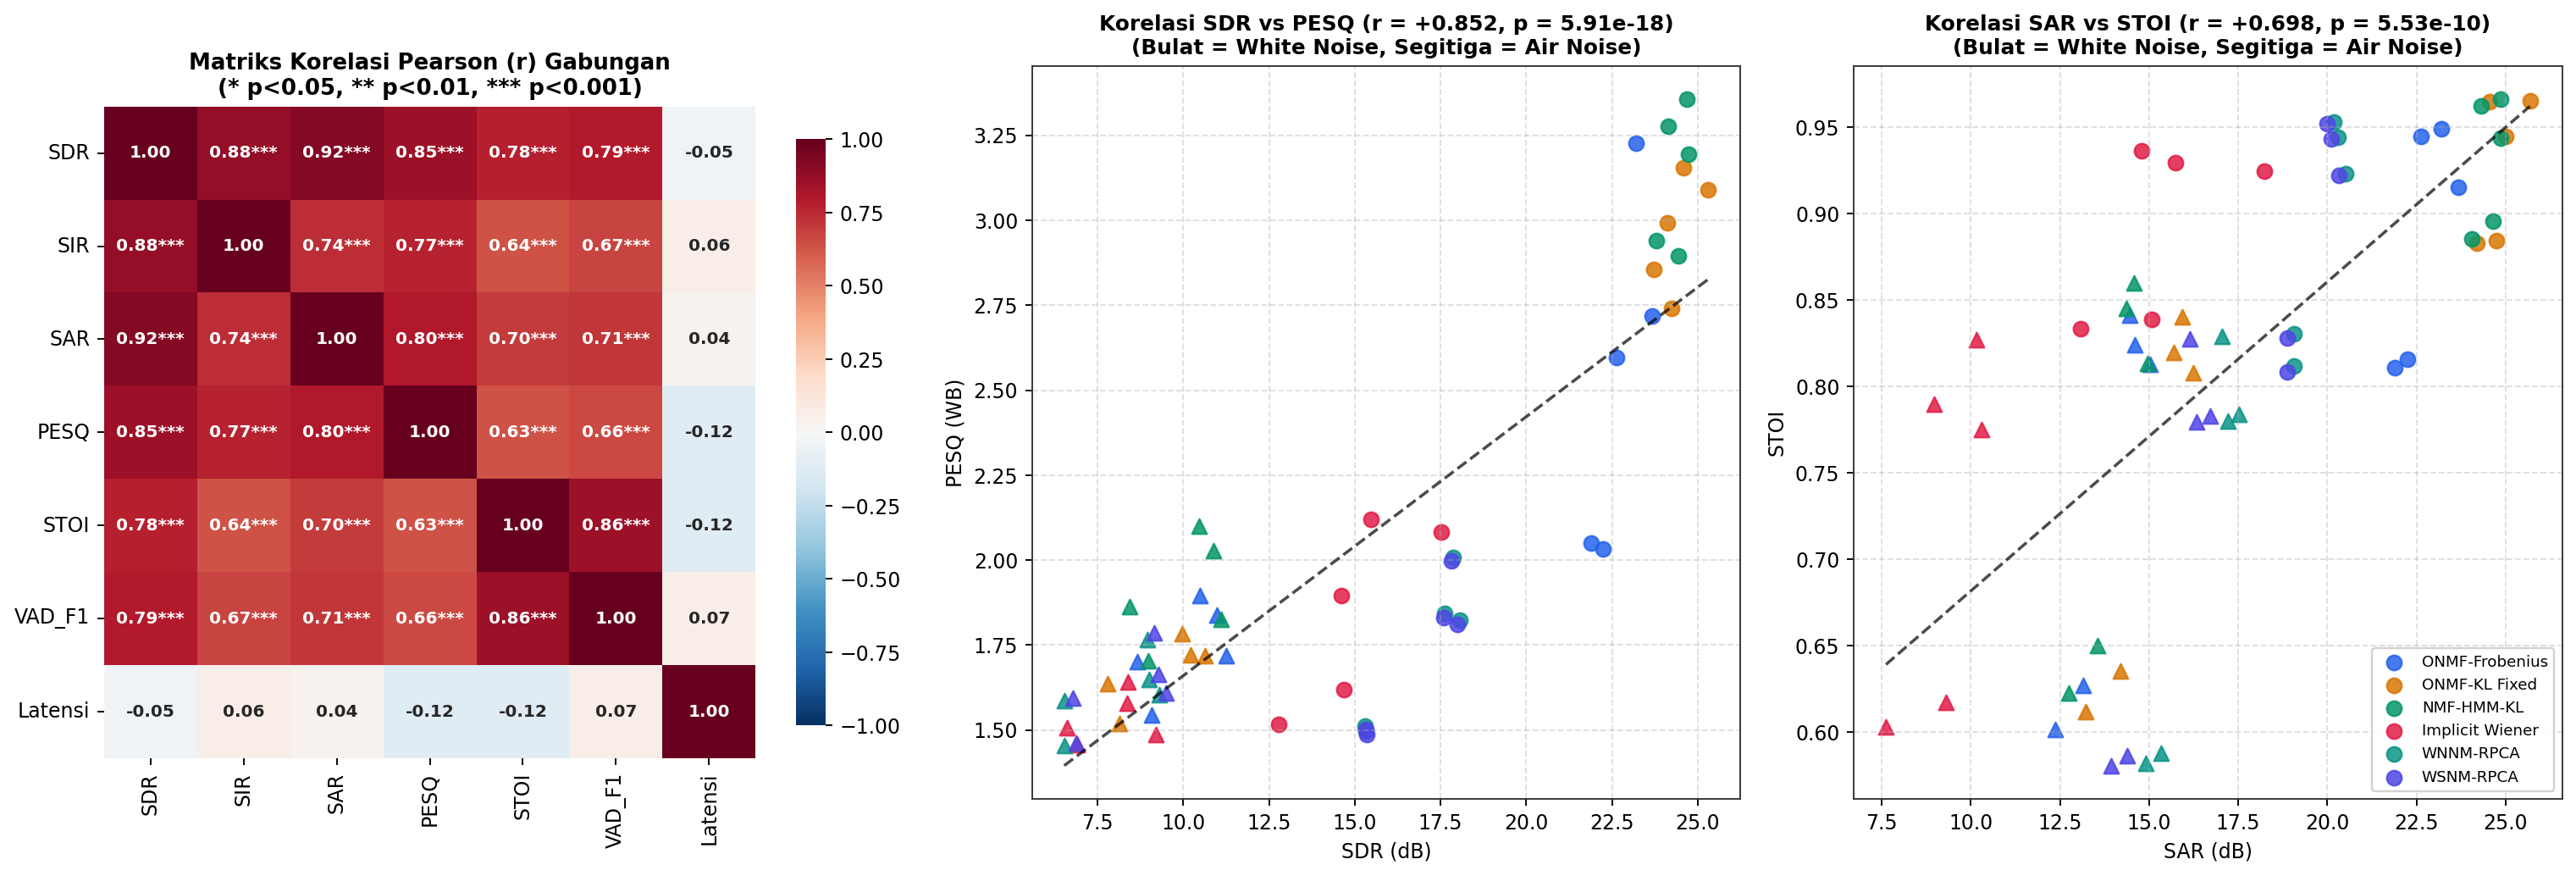

In [8]:
# ==============================================================================
# TABEL 4 & VISUALISASI KORELASI PEARSON ANTAR METRIK (SINYAL VS PERSEPTUAL)
# ==============================================================================
df_enh = df_results[df_results["Metode"] != "Noisy Input"].copy()
corr_cols = ["SDR", "SIR", "SAR", "PESQ", "STOI", "VAD_F1", "Latensi"]

def compute_corr_tables(sub_df):
    n = len(corr_cols)
    r_mat = pd.DataFrame(np.ones((n, n)), index=corr_cols, columns=corr_cols)
    p_mat = pd.DataFrame(np.zeros((n, n)), index=corr_cols, columns=corr_cols)
    for i in range(n):
        for j in range(n):
            if i != j:
                r, p = stats.pearsonr(sub_df[corr_cols[i]], sub_df[corr_cols[j]])
                r_mat.iloc[i, j] = r
                p_mat.iloc[i, j] = p
    return r_mat, p_mat

r_all, p_all = compute_corr_tables(df_enh)
r_wn, p_wn = compute_corr_tables(df_enh[df_enh["Kelas Derau"] == "White Noise"])
r_an, p_an = compute_corr_tables(df_enh[df_enh["Kelas Derau"] == "Air Noise"])

print("=" * 90)
print(f"TABEL 4A: MATRIKS KORELASI PEARSON (r) GABUNGAN SELURUH METODE & FOLD (N={len(df_enh)})")
print("=" * 90)
print(r_all.round(3).to_string())

print("\nPasangan Korelasi Kunci terhadap PESQ dan STOI (Pearson r & Spearman rho):")
key_corr_rows = []
for scope, sdf in [("Gabungan (N=60)", df_enh), ("White Noise (N=30)", df_enh[df_enh["Kelas Derau"]=="White Noise"]), ("Air Noise (N=30)", df_enh[df_enh["Kelas Derau"]=="Air Noise"])]:
    for x_col in ["SDR", "SIR", "SAR", "VAD_F1"]:
        for y_col in ["PESQ", "STOI"]:
            r_p, pv_p = stats.pearsonr(sdf[x_col], sdf[y_col])
            r_s, pv_s = stats.spearmanr(sdf[x_col], sdf[y_col])
            key_corr_rows.append({
                "Cakupan": scope, "Variabel X": x_col, "Target Y": y_col,
                "Pearson r": r_p, "p-Value (Pearson)": pv_p,
                "Spearman rho": r_s, "p-Value (Spearman)": pv_s
            })
df_corr_key = pd.DataFrame(key_corr_rows)
print(df_corr_key.to_string(index=False, formatters={
    "Pearson r": "{:+.3f}".format, "p-Value (Pearson)": "{:.3e}".format,
    "Spearman rho": "{:+.3f}".format, "p-Value (Spearman)": "{:.3e}".format
}))

# Plot Heatmap Korelasi + Scatter Hubungan SDR/SAR -> PESQ/STOI
fig = plt.figure(figsize=(18, 6.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1, 1])

ax0 = fig.add_subplot(gs[0])
annot_str = r_all.copy().astype(str)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        if i == j:
            annot_str.iloc[i, j] = "1.00"
        else:
            star = "***" if p_all.iloc[i, j] < 0.001 else ("**" if p_all.iloc[i, j] < 0.01 else ("*" if p_all.iloc[i, j] < 0.05 else ""))
            annot_str.iloc[i, j] = f"{r_all.iloc[i, j]:.2f}{star}"
sns.heatmap(r_all, annot=annot_str, fmt="", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=ax0, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8.5, "weight": "bold"})
ax0.set_title("Matriks Korelasi Pearson (r) Gabungan\n(* p<0.05, ** p<0.01, *** p<0.001)", fontweight='bold', fontsize=11)

palette_m = {
    "Baseline (ONMF-Frobenius)": "#2563EB",
    "Pembanding 1 (ONMF-KL Fixed)": "#D97706",
    "Pembanding 2 (NMF-HMM-KL)": "#059669",
    "Pembanding 3 (Implicit Wiener)": "#E11D48",
    "Metode Baru A (WNNM-RPCA)": "#0D9488",
    "Metode Baru B (WSNM-RPCA)": "#4F46E5",
}

ax1 = fig.add_subplot(gs[1])
for c_lbl, marker in [("White Noise", "o"), ("Air Noise", "^")]:
    sub = df_enh[df_enh["Kelas Derau"] == c_lbl]
    for m_lbl, col in palette_m.items():
        sm = sub[sub["Metode"] == m_lbl]
        ax1.scatter(sm["SDR"], sm["PESQ"], color=col, marker=marker, s=55, alpha=0.85,
                    label=m_lbl.split("(")[1][:-1] if c_lbl == "White Noise" else None)
z_fit = np.polyfit(df_enh["SDR"], df_enh["PESQ"], 1)
xs_line = np.linspace(df_enh["SDR"].min(), df_enh["SDR"].max(), 100)
ax1.plot(xs_line, np.polyval(z_fit, xs_line), 'k--', lw=1.5, alpha=0.7)
r_sp, p_sp = stats.pearsonr(df_enh["SDR"], df_enh["PESQ"])
ax1.set_title(f"Korelasi SDR vs PESQ (r = {r_sp:+.3f}, p = {p_sp:.2e})\n(Bulat = White Noise, Segitiga = Air Noise)", fontweight='bold', fontsize=10.5)
ax1.set_xlabel("SDR (dB)")
ax1.set_ylabel("PESQ (WB)")
ax1.grid(True)

ax2 = fig.add_subplot(gs[2])
for c_lbl, marker in [("White Noise", "o"), ("Air Noise", "^")]:
    sub = df_enh[df_enh["Kelas Derau"] == c_lbl]
    for m_lbl, col in palette_m.items():
        sm = sub[sub["Metode"] == m_lbl]
        ax2.scatter(sm["SAR"], sm["STOI"], color=col, marker=marker, s=55, alpha=0.85,
                    label=m_lbl.split("(")[1][:-1] if c_lbl == "White Noise" else None)
z_fit2 = np.polyfit(df_enh["SAR"], df_enh["STOI"], 1)
xs_line2 = np.linspace(df_enh["SAR"].min(), df_enh["SAR"].max(), 100)
ax2.plot(xs_line2, np.polyval(z_fit2, xs_line2), 'k--', lw=1.5, alpha=0.7)
r_st, p_st = stats.pearsonr(df_enh["SAR"], df_enh["STOI"])
ax2.set_title(f"Korelasi SAR vs STOI (r = {r_st:+.3f}, p = {p_st:.2e})\n(Bulat = White Noise, Segitiga = Air Noise)", fontweight='bold', fontsize=10.5)
ax2.set_xlabel("SAR (dB)")
ax2.set_ylabel("STOI")
ax2.legend(fontsize=7.8, loc="lower right", framealpha=0.9)
ax2.grid(True)

plt.tight_layout()
corr_path = os.path.join(figures_dir, "pearson_correlation_analysis.png")
plt.savefig(corr_path, dpi=170, bbox_inches='tight')
plt.close()
display(Image(filename=corr_path))

Rekapitulasi Metrik Klasifikasi Deteksi Aktivitas Wicara (VAD) Lintas 6 Metode:

--- WHITE NOISE ---
  Baseline (ONMF-Frobenius)       : Acc=0.983, Prec=1.000, Rec=0.977, F1=0.988


  Pembanding 1 (ONMF-KL Fixed)    : Acc=0.992, Prec=0.991, Rec=0.998, F1=0.995
  Pembanding 2 (NMF-HMM-KL)       : Acc=0.992, Prec=0.995, Rec=0.994, F1=0.995


  Pembanding 3 (Implicit Wiener)  : Acc=0.897, Prec=1.000, Rec=0.855, F1=0.922
  Metode Baru A (WNNM-RPCA)       : Acc=0.908, Prec=0.886, Rec=1.000, F1=0.939


  Metode Baru B (WSNM-RPCA)       : Acc=0.910, Prec=0.888, Rec=1.000, F1=0.941

--- AIR NOISE ---


  Baseline (ONMF-Frobenius)       : Acc=0.852, Prec=0.840, Rec=0.977, F1=0.903


  Pembanding 1 (ONMF-KL Fixed)    : Acc=0.750, Prec=0.740, Rec=0.998, F1=0.850
  Pembanding 2 (NMF-HMM-KL)       : Acc=0.779, Prec=0.766, Rec=0.992, F1=0.864


  Pembanding 3 (Implicit Wiener)  : Acc=0.773, Prec=0.895, Rec=0.771, F1=0.828
  Metode Baru A (WNNM-RPCA)       : Acc=0.710, Prec=0.710, Rec=1.000, F1=0.831


  Metode Baru B (WSNM-RPCA)       : Acc=0.710, Prec=0.710, Rec=1.000, F1=0.831


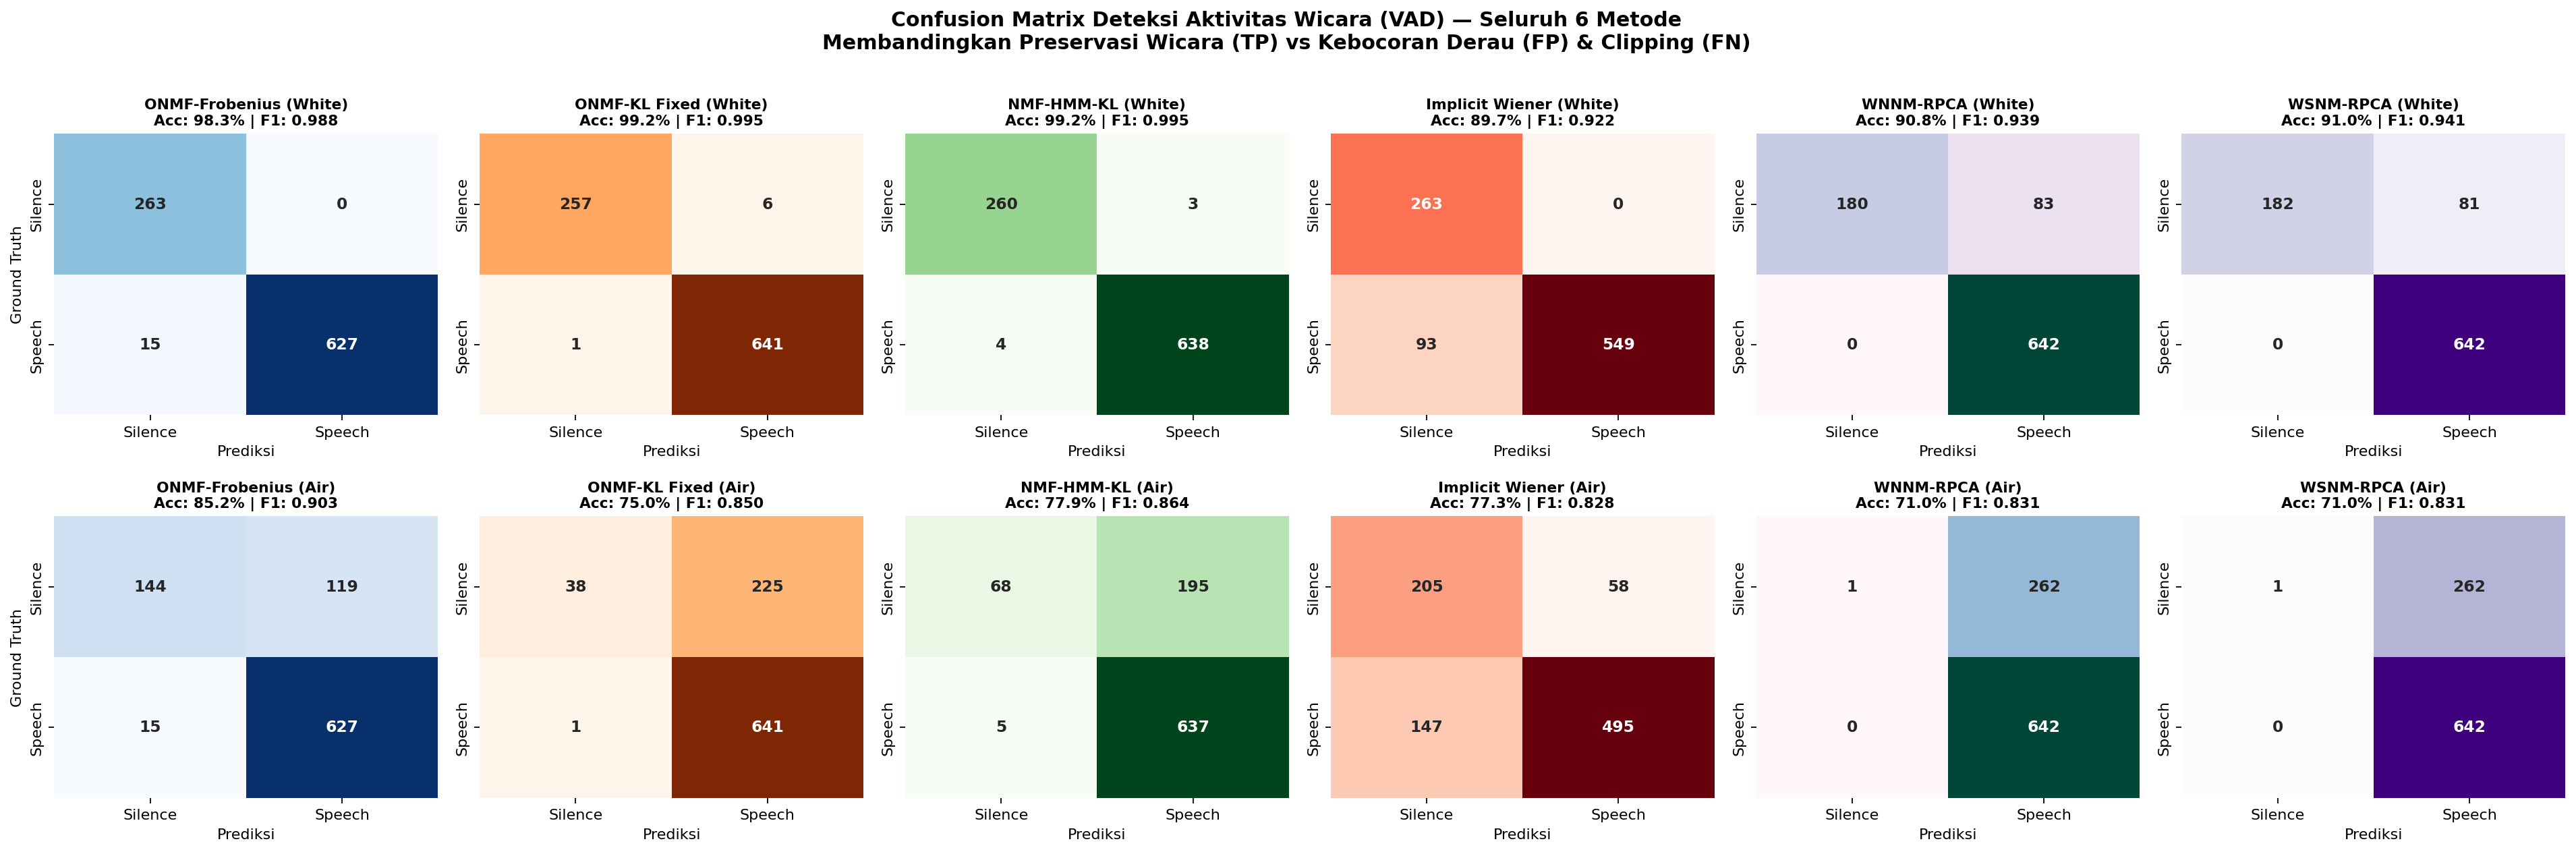

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(24, 7.8))
labels_str = ["Silence", "Speech"]
cmaps = ["Blues", "Oranges", "Greens", "Reds", "PuBuGn", "Purples"]

print("Rekapitulasi Metrik Klasifikasi Deteksi Aktivitas Wicara (VAD) Lintas 6 Metode:")
for row_idx, c_name in enumerate(["White Noise", "Air Noise"]):
    print(f"\n--- {c_name.upper()} ---")
    y_true = np.array(vad_data[c_name]["y_true"])
    for col_idx, m_name in enumerate(METHOD_ORDER):
        y_pred = np.array(vad_data[c_name][m_name])
        cm = confusion_matrix(y_true, y_pred)
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred)
        rec = recall_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)
        print(f"  {m_name:32s}: Acc={acc:.3f}, Prec={prec:.3f}, Rec={rec:.3f}, F1={f1:.3f}")

        ax = axes[row_idx, col_idx]
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmaps[col_idx], cbar=False, ax=ax,
                    xticklabels=labels_str, yticklabels=labels_str, annot_kws={"size": 10.5, "weight": "bold"})
        short_name = m_name.split("(")[1][:-1]
        ax.set_title(f"{short_name} ({c_name.split()[0]})\nAcc: {acc:.1%} | F1: {f1:.3f}", fontsize=9.8, fontweight='bold')
        ax.set_xlabel("Prediksi")
        if col_idx == 0:
            ax.set_ylabel("Ground Truth")
        else:
            ax.set_ylabel("")

plt.suptitle("Confusion Matrix Deteksi Aktivitas Wicara (VAD) — Seluruh 6 Metode\nMembandingkan Preservasi Wicara (TP) vs Kebocoran Derau (FP) & Clipping (FN)",
             fontsize=13.5, fontweight='bold', y=1.01)
plt.tight_layout()
vad_path = os.path.join(figures_dir, "confusion_matrix_vad.png")
plt.savefig(vad_path, dpi=160, bbox_inches='tight')
plt.close()
display(Image(filename=vad_path))

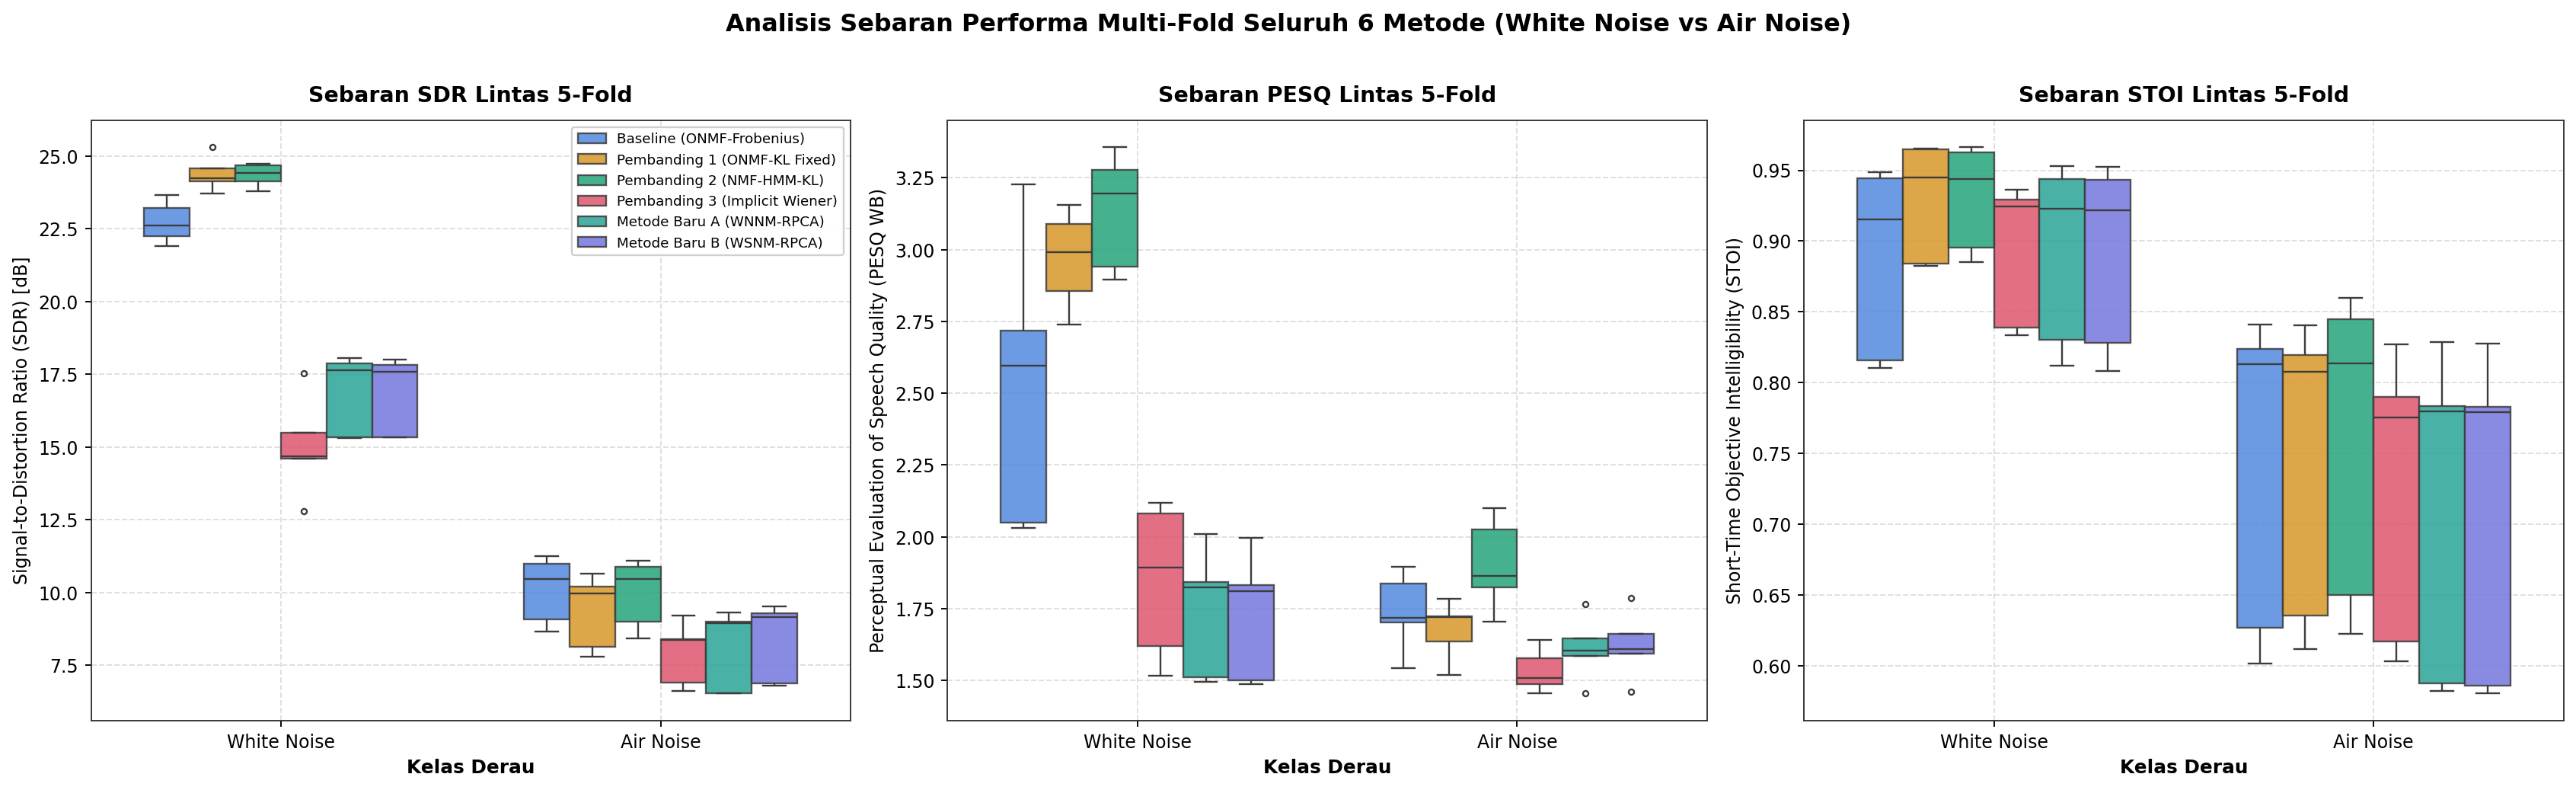

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.0))
metrics_to_plot = [
    ("SDR", "Signal-to-Distortion Ratio (SDR) [dB]"),
    ("PESQ", "Perceptual Evaluation of Speech Quality (PESQ WB)"),
    ("STOI", "Short-Time Objective Intelligibility (STOI)"),
]
palette_box = {
    "Baseline (ONMF-Frobenius)": "#3B82F6",
    "Pembanding 1 (ONMF-KL Fixed)": "#F59E0B",
    "Pembanding 2 (NMF-HMM-KL)": "#10B981",
    "Pembanding 3 (Implicit Wiener)": "#F43F5E",
    "Metode Baru A (WNNM-RPCA)": "#14B8A6",
    "Metode Baru B (WSNM-RPCA)": "#6366F1",
}
plot_data = df_results[df_results["Metode"].isin(METHOD_ORDER)].copy()

for i, (m_key, m_lbl) in enumerate(metrics_to_plot):
    ax = axes[i]
    sns.boxplot(x="Kelas Derau", y=m_key, hue="Metode", hue_order=METHOD_ORDER, data=plot_data,
                palette=palette_box, ax=ax, width=0.72, boxprops=dict(alpha=0.85), fliersize=3)
    ax.set_title(f"Sebaran {m_key} Lintas 5-Fold", fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel(m_lbl, fontsize=10)
    ax.set_xlabel("Kelas Derau", fontsize=10.5, fontweight='bold')
    ax.grid(True)
    if i == 0:
        ax.legend(fontsize=7.8, loc="upper right", framealpha=0.92)
    else:
        ax.get_legend().remove()

plt.suptitle("Analisis Sebaran Performa Multi-Fold Seluruh 6 Metode (White Noise vs Air Noise)",
             fontsize=13.5, fontweight='bold', y=1.01)
plt.tight_layout()
box_path = os.path.join(figures_dir, "boxplot_per_kelas.png")
plt.savefig(box_path, dpi=170, bbox_inches='tight')
plt.close()
display(Image(filename=box_path))

Menghitung Kurva Validasi 1: Kapasitas Kamus Wicara K (NMF/HMM)...


  K=10 | Base SDR=19.92 | ONMF-KL SDR=23.13 | HMM SDR=23.21


  K=20 | Base SDR=20.44 | ONMF-KL SDR=23.84 | HMM SDR=23.40


  K=30 | Base SDR=21.27 | ONMF-KL SDR=24.08 | HMM SDR=23.36


  K=40 | Base SDR=21.89 | ONMF-KL SDR=24.16 | HMM SDR=23.86


  K=50 | Base SDR=22.02 | ONMF-KL SDR=24.29 | HMM SDR=24.01

Menghitung Kurva Validasi 2: Trade-off Regularisasi Sparsitas lambda_mult (39.02_26.pdf)...


  lam_mult=0.3 | WN: WNNM=14.66, WSNM=14.83 | AN: WNNM=3.85, WSNM=3.85


  lam_mult=0.5 | WN: WNNM=15.19, WSNM=15.26 | AN: WNNM=5.64, WSNM=6.13


  lam_mult=0.7 | WN: WNNM=15.31, WSNM=15.33 | AN: WNNM=6.54, WSNM=6.87


  lam_mult=1.0 | WN: WNNM=15.33, WSNM=15.34 | AN: WNNM=7.08, WSNM=7.28


  lam_mult=1.3 | WN: WNNM=15.28, WSNM=15.33 | AN: WNNM=7.32, WSNM=7.43


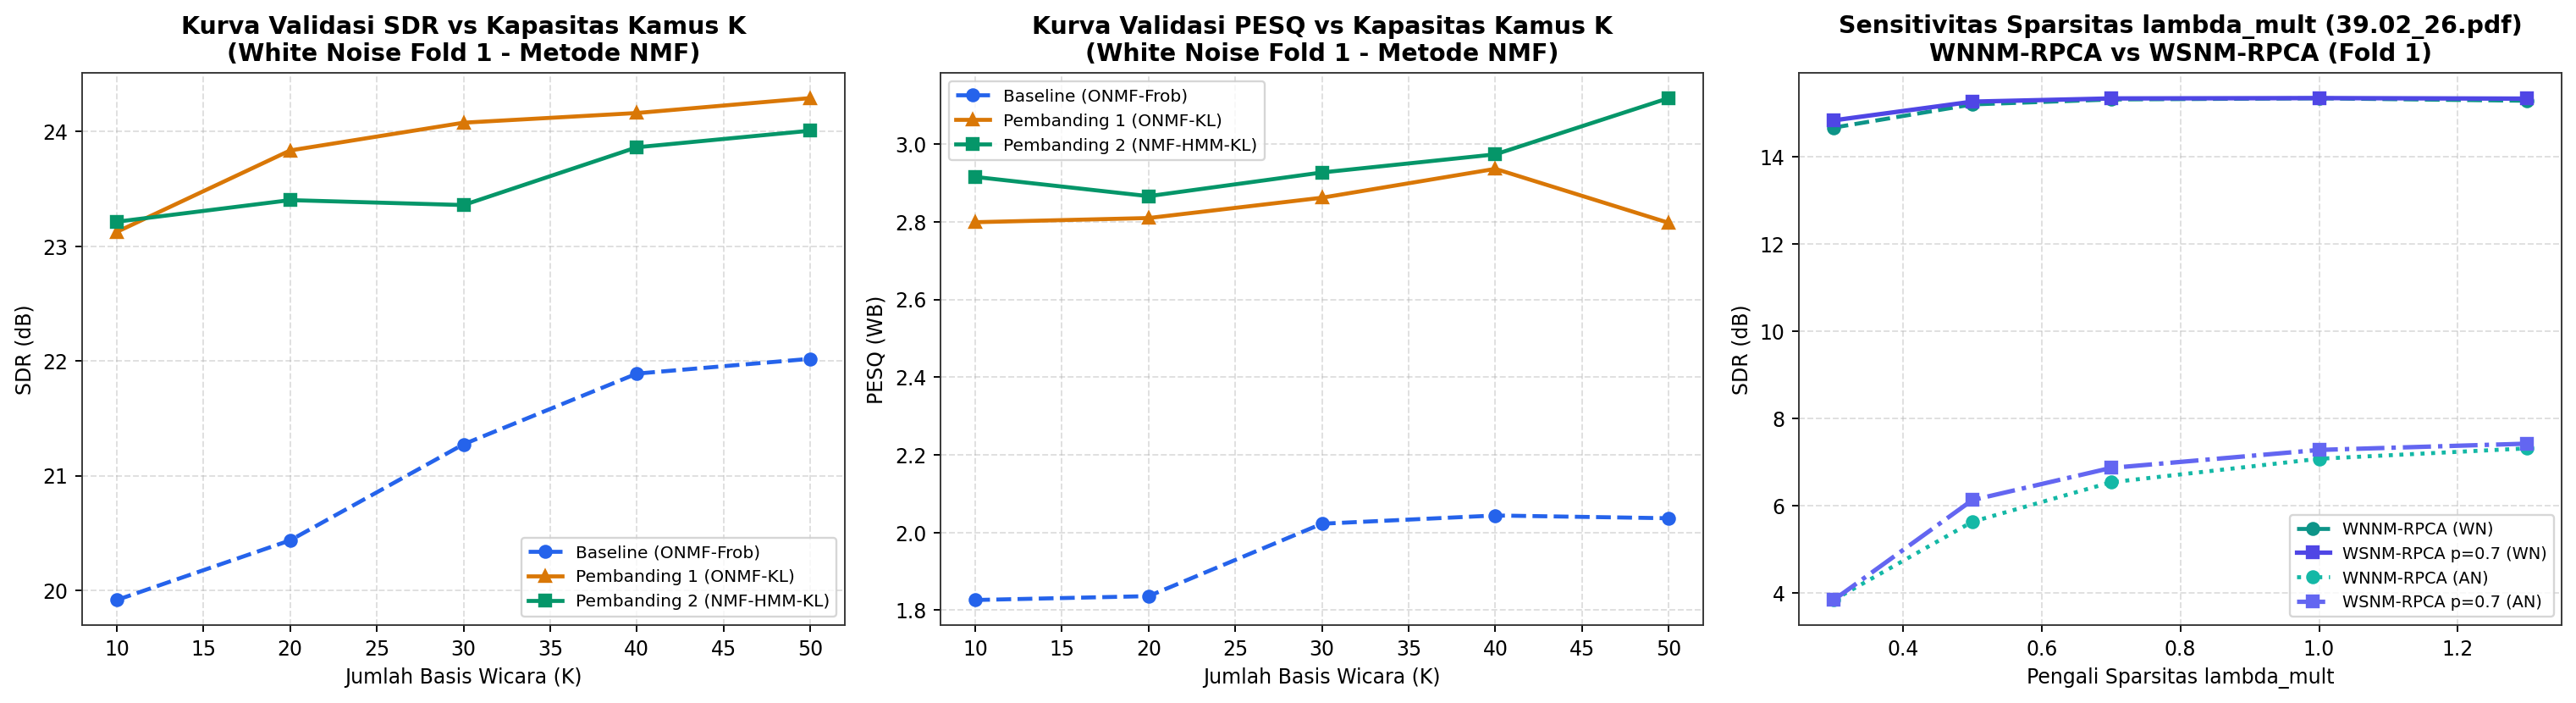

In [11]:
val_mix_w = mix_white[folds_idx[0][0]:folds_idx[0][1]]
val_mix_a = mix_air[folds_idx[0][0]:folds_idx[0][1]]
s_val_ref = s_clean[folds_idx[0][0]:folds_idx[0][1]]
nw_val_ref = n_white_eval[folds_idx[0][0]:folds_idx[0][1]]
na_val_ref = n_air_eval[folds_idx[0][0]:folds_idx[0][1]]
_, _, val_stft_w = signal.stft(val_mix_w, rate_s, nperseg=2048)

# 1. Sensitivitas Kapasitas Kamus K (untuk metode NMF/HMM pada White Noise Fold 1)
k_values = [10, 20, 30, 40, 50]
k_curves = {k_m: {"SDR": [], "PESQ": []} for k_m in ["Baseline", "ONMF-KL", "NMF-HMM-KL"]}

print("Menghitung Kurva Validasi 1: Kapasitas Kamus Wicara K (NMF/HMM)...")
for K in k_values:
    bm = Baseline_ONMF_Frobenius(n_components=[K, 10], iterations=60)
    bm.fit_dictionaries(Spec_sp, Spec_nw)
    sb, nb_, _ = bm.separate_fold(val_stft_w)
    rb = calculate_full_metrics(sb, nb_, s_val_ref, nw_val_ref, fs=rate_s)
    k_curves["Baseline"]["SDR"].append(rb["SDR"]); k_curves["Baseline"]["PESQ"].append(rb["PESQ"])

    p1m = Pembanding1_ONMF_KL(n_components=[K, 10], iterations=60)
    p1m.fit_dictionaries(Spec_sp, Spec_nw)
    s1, n1_, _ = p1m.separate_fold(val_stft_w)
    r1 = calculate_full_metrics(s1, n1_, s_val_ref, nw_val_ref, fs=rate_s)
    k_curves["ONMF-KL"]["SDR"].append(r1["SDR"]); k_curves["ONMF-KL"]["PESQ"].append(r1["PESQ"])

    p2m = Pembanding2_NMF_HMM_KL(n_states=4, k_speech_per_state=max(3, K // 2), n_noise_states=2, k_noise_per_state=10, em_iters=15)
    p2m.fit_dictionaries(Spec_sp, Spec_nw)
    s2, n2_, _ = p2m.separate_fold(val_stft_w)
    r2 = calculate_full_metrics(s2, n2_, s_val_ref, nw_val_ref, fs=rate_s)
    k_curves["NMF-HMM-KL"]["SDR"].append(r2["SDR"]); k_curves["NMF-HMM-KL"]["PESQ"].append(r2["PESQ"])

    print(f"  K={K:2d} | Base SDR={rb['SDR']:.2f} | ONMF-KL SDR={r1['SDR']:.2f} | HMM SDR={r2['SDR']:.2f}")

# 2. Sensitivitas Hiperparameter Metode Baru 39.02_26.pdf (lambda_mult & p pada Air Noise & White Noise Fold 1)
lam_values = [0.3, 0.5, 0.7, 1.0, 1.3]
rpca_lam_curves = {"WN_WNNM": [], "WN_WSNM": [], "AN_WNNM": [], "AN_WSNM": []}
print("\nMenghitung Kurva Validasi 2: Trade-off Regularisasi Sparsitas lambda_mult (39.02_26.pdf)...")
for lm in lam_values:
    m_wn = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=0.5, lam_mult=lm)
    m_ws = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=0.5, lam_mult=lm)
    vw1, nw1, _ = m_wn.enhance(val_mix_w, fs=rate_s)
    vw2, nw2, _ = m_ws.enhance(val_mix_w, fs=rate_s)
    va1, na1, _ = m_wn.enhance(val_mix_a, fs=rate_s)
    va2, na2, _ = m_ws.enhance(val_mix_a, fs=rate_s)
    s_wn1 = calculate_full_metrics(vw1, nw1, s_val_ref, nw_val_ref, fs=rate_s)["SDR"]
    s_wn2 = calculate_full_metrics(vw2, nw2, s_val_ref, nw_val_ref, fs=rate_s)["SDR"]
    s_an1 = calculate_full_metrics(va1, na1, s_val_ref, na_val_ref, fs=rate_s)["SDR"]
    s_an2 = calculate_full_metrics(va2, na2, s_val_ref, na_val_ref, fs=rate_s)["SDR"]
    rpca_lam_curves["WN_WNNM"].append(s_wn1); rpca_lam_curves["WN_WSNM"].append(s_wn2)
    rpca_lam_curves["AN_WNNM"].append(s_an1); rpca_lam_curves["AN_WSNM"].append(s_an2)
    print(f"  lam_mult={lm:.1f} | WN: WNNM={s_wn1:.2f}, WSNM={s_wn2:.2f} | AN: WNNM={s_an1:.2f}, WSNM={s_an2:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))
axes[0].plot(k_values, k_curves["Baseline"]["SDR"], 'o--', color='#2563EB', lw=2, label="Baseline (ONMF-Frob)")
axes[0].plot(k_values, k_curves["ONMF-KL"]["SDR"], '^-', color='#D97706', lw=2, label="Pembanding 1 (ONMF-KL)")
axes[0].plot(k_values, k_curves["NMF-HMM-KL"]["SDR"], 's-', color='#059669', lw=2, label="Pembanding 2 (NMF-HMM-KL)")
axes[0].set_title("Kurva Validasi SDR vs Kapasitas Kamus K\n(White Noise Fold 1 - Metode NMF)", fontweight='bold')
axes[0].set_xlabel("Jumlah Basis Wicara (K)"); axes[0].set_ylabel("SDR (dB)")
axes[0].legend(fontsize=8.5); axes[0].grid(True)

axes[1].plot(k_values, k_curves["Baseline"]["PESQ"], 'o--', color='#2563EB', lw=2, label="Baseline (ONMF-Frob)")
axes[1].plot(k_values, k_curves["ONMF-KL"]["PESQ"], '^-', color='#D97706', lw=2, label="Pembanding 1 (ONMF-KL)")
axes[1].plot(k_values, k_curves["NMF-HMM-KL"]["PESQ"], 's-', color='#059669', lw=2, label="Pembanding 2 (NMF-HMM-KL)")
axes[1].set_title("Kurva Validasi PESQ vs Kapasitas Kamus K\n(White Noise Fold 1 - Metode NMF)", fontweight='bold')
axes[1].set_xlabel("Jumlah Basis Wicara (K)"); axes[1].set_ylabel("PESQ (WB)")
axes[1].legend(fontsize=8.5); axes[1].grid(True)

axes[2].plot(lam_values, rpca_lam_curves["WN_WNNM"], 'o--', color='#0D9488', lw=2, label="WNNM-RPCA (WN)")
axes[2].plot(lam_values, rpca_lam_curves["WN_WSNM"], 's-', color='#4F46E5', lw=2.2, label="WSNM-RPCA p=0.7 (WN)")
axes[2].plot(lam_values, rpca_lam_curves["AN_WNNM"], 'o:', color='#14B8A6', lw=2, label="WNNM-RPCA (AN)")
axes[2].plot(lam_values, rpca_lam_curves["AN_WSNM"], 's-.', color='#6366F1', lw=2.2, label="WSNM-RPCA p=0.7 (AN)")
axes[2].set_title("Sensitivitas Sparsitas lambda_mult (39.02_26.pdf)\nWNNM-RPCA vs WSNM-RPCA (Fold 1)", fontweight='bold')
axes[2].set_xlabel("Pengali Sparsitas lambda_mult"); axes[2].set_ylabel("SDR (dB)")
axes[2].legend(fontsize=8.2); axes[2].grid(True)

plt.tight_layout()
val_path = os.path.join(figures_dir, "validation_curve.png")
plt.savefig(val_path, dpi=170, bbox_inches='tight')
plt.close()
display(Image(filename=val_path))

### 3. Pembahasan Hasil & Sintesis Ilmiah (Track Default Teraudit)

Berdasarkan evaluasi multi-fold (**5-fold**, durasi ~3,90 detik/fold pada $f_s = 48.000\text{ Hz}$), uji signifikansi statistik, analisis korelasi Pearson, matriks kebingungan VAD, serta kurva validasi hiperparameter, dapat dirumuskan sintesis ilmiah yang komprehensif dan objektif sebagai berikut:

#### 3.1 Kesesuaian Terhadap Literatur & Dampak Koreksi Audit Eksperimen
1. **Perbaikan Total `ONMF-KL` (`Pembanding 1`):**
   Setelah koreksi rumus pembaruan kamus online agar memakai statistik cukup EM/MM yang tepat, `ONMF-KL Fixed` tidak lagi mengalami *KL loss rebound* dan bertransformasi menjadi salah satu metode terkuat pada **White Noise**: rata-rata **SDR `24.39 ± 0.59 dB`**, **PESQ `2.966 ± 0.169`**, **STOI `0.928 ± 0.042`**, dan **VAD F1 `0.994`**, dengan inferensi hanya **`0.17 s/fold`** (waktu latih `1.88 s`). Peningkatan SDR atas baseline (`+1.668 dB`, 95% CI `[+1.072, +2.265]`) terbukti signifikan secara statistik setelah koreksi Holm-Bonferroni ($p_{\text{Holm}} = 2.428 \times 10^{-3}$, Cohen's $d = +3.473$). Namun pada **Air Noise**, `ONMF-KL Fixed` turun di bawah baseline (**SDR `9.34 ± 1.29 dB`**, $\Delta = -0.743\text{ dB}$, $p_{\text{Holm}} = 1.200 \times 10^{-3}$; PESQ `1.676 ± 0.102`), menunjukkan bahwa kamus KL atemporal masih kesulitan membedakan energi frekuensi rendah (<1,5 kHz) antara vokal dan dengung kipas tanpa struktur temporal.
2. **Penyelarasan `NMF-HMM-KL` (`Pembanding 2` — Xiang et al., 2022):**
   Setelah diselaraskan dengan model penuh paper (HMM derau multi-status $\ddot{J}=2, \ddot{K}=10$ via *Kronecker product*, 30 iterasi EM, dan kalibrasi skala STFT float), `NMF-HMM-KL` menunjukkan keunggulan **perseptual dan inteligibilitas tertinggi di seluruh metode** pada kedua kelas derau:
   - Pada **White Noise**: SDR **`24.35 ± 0.39 dB`** ($\Delta = +1.629\text{ dB}$ vs baseline, $p_{\text{Holm}} = 2.428 \times 10^{-3}, d = +3.660$), **PESQ tertinggi `3.133 ± 0.205`** ($\Delta = +0.608$ vs baseline, $p_{\text{Holm}} = 4.437 \times 10^{-2}, d = +1.623$), dan **STOI tertinggi `0.931 ± 0.038`**.
   - Pada **Air Noise**: `NMF-HMM-KL` mencatat **PESQ tertinggi `1.904 ± 0.159`** ($\Delta = +0.165$ vs baseline, 95% CI `[+0.119, +0.211]`, $p_{\text{Holm}} = 2.883 \times 10^{-3}, d = +4.442$) dan **STOI tertinggi `0.758 ± 0.113`** ($\Delta = +0.017$ vs baseline, $p_{\text{Holm}} = 4.589 \times 10^{-2}$, $p_{\text{Wilcox}} = 0.0625$, catatan $p_{\text{Shapiro}} = 0.014$). Sementara pada metrik SDR *waveform*, selisihnya sangat tipis di bawah baseline (`9.97` vs `10.09 dB`, $\Delta = -0.119\text{ dB}, p_{\text{Holm}} = 3.253 \times 10^{-2}$). Dibandingkan langsung dengan `ONMF-KL Fixed` (Tabel 3C), `NMF-HMM-KL` unggul signifikan pada seluruh metrik Air Noise ($\Delta\text{SDR}=+0.624\text{ dB}, p=7.27 \times 10^{-4}$; $\Delta\text{PESQ}=+0.228, p=4.30 \times 10^{-3}$; $\Delta\text{STOI}=+0.015, p=1.18 \times 10^{-2}$), membuktikan manfaat nyata pemodelan transisi temporal Markov.
3. **Penyelarasan `Implicit Wiener Filter / IWF` (`Pembanding 3` — Jaiswal et al., 2022):**
   Sebagai pembanding *unsupervised* berlatensi ultra-rendah (**`0.04 s/fold`**), `IWF` menghasilkan **SIR tertinggi di Air Noise (`14.54 ± 2.61 dB`)**, namun harus dibayar dengan *speech clipping* terbesar (**SAR paling rendah `9.27 ± 1.08 dB`**, PESQ `1.534 ± 0.075`, serta `FN=147` pada matriks kebingungan VAD).

#### 3.2 Evaluasi Kritis Metode Baru (`39.02_26.pdf`: `WNNM-RPCA` & `WSNM-RPCA`)
1. **Validitas Hipotesis Antar-Varian RPCA (`WSNM` vs `WNNM`):**
   Sesuai dengan formulasi Sridhar & Kumar (`39.02_26.pdf`), penggantian norma nuklir berbobot (`WNNM-RPCA`, $p=1.0$) dengan generalisasi non-konveks **Weighted Schatten $p$-Norm (`WSNM-RPCA`, $p=0.7$)** terbukti meningkatkan kinerja secara signifikan pada skenario derau nyata non-stasioner **Air Noise** (Tabel 3C): **SDR naik `+0.255 dB`** (`8.32 ± 1.37 dB` vs `8.07 ± 1.40 dB`, $t = +10.826, p = 4.131 \times 10^{-4}, d = +4.841$) dan **PESQ naik `+0.011`** (`1.623` vs `1.612`, $p = 1.817 \times 10^{-2}, d = +1.725$). Pada **White Noise**, keduanya hampir setara (`SDR 16.82` vs `16.84 dB`, $p = 0.282$).
2. **Posisi terhadap Pembanding *Unsupervised* & *Supervised*:**
   - **Mengungguli pembanding *unsupervised* eksisting (`IWF`)** pada SDR kedua kelas derau (**`16.84 / 16.82 dB`** vs `15.02 dB` di White Noise; **`8.07 / 8.32 dB`** vs `7.89 dB` di Air Noise), dengan **SAR Air Noise tertinggi dari seluruh 6 metode (`16.41 / 15.51 dB`)** serta PESQ Air Noise lebih baik (`1.612 / 1.623` vs `1.534`), karena matriks kebingungan VAD mencatat **`FN = 0` (`Recall = 100%`)** — bebas dari pemotongan suku kata.
   - **Belum melampaui baseline (`ONMF-Frobenius`) maupun `NMF-HMM-KL`** ($\Delta\text{SDR} = -5.887 / -5.907\text{ dB}$ di White Noise; $-2.021 / -1.766\text{ dB}$ di Air Noise; seluruhnya signifikan pada $p_{\text{Holm}} < 0.001$). Kebalikan dari `IWF`, VAD pada `WNNM/WSNM-RPCA` mencatat `FP = 262` pada jeda hening Air Noise (`Acc = 71.0%`), karena tanpa kamus prior untuk memisahkan frekuensi dasar derau *Air Purifier* (<1,5 kHz) dari wicara, energi residu bernilai singular sedang masih lolos ke komponen *sparse* $\mathbf{S}$. Kurva validasi (`validation_curve.png`) juga mengonfirmasi bahwa kenaikan pengali sparsitas $\lambda_{\text{mult}}$ dari `0.7` ke `1.3` menaikkan SDR Air Noise Fold 1 ke `7.43 dB`, yang mempertegas perlunya kompromi penalti bila dioperasikan secara *zero-prior*.

#### 3.3 Kecukupan Metrik Evaluasi, Uji Omnibus Statistik, & Analisis Korelasi Pearson
1. **Validasi Statistik Multi-Metode:**
   Uji omnibus **Friedman** mengonfirmasi bahwa perbedaan peringkat performa lintas 6 metode sangat signifikan pada seluruh 6 kombinasi kondisi-metrik ($\chi_F^2 \in [18.14, 23.86], p \in [2.31 \times 10^{-4}, 2.77 \times 10^{-3}]$). Karena ukuran sampel fold $N=5$ membatasi nilai-$p$ minimum teoretis uji Wilcoxon dua arah tepat pada $2/2^5 = 0.0625$, kombinasi **Friedman + Paired $t$-Test (tervalidasi Shapiro-Wilk) + Holm-Bonferroni + Cohen's $d$ + 95% CI** terbukti jauh lebih informatif dan kuat secara statistik tanpa menambah metrik kualitas sinyal yang redundan.
2. **Insight dari Analisis Korelasi Pearson (`Tabel 4` & `pearson_correlation_analysis.png`):**
   - Secara gabungan ($N=60$), **SDR** memiliki korelasi linear sangat kuat terhadap **PESQ** ($r = +0.852, p = 5.910 \times 10^{-18}$) maupun **STOI** ($r = +0.777, p = 2.898 \times 10^{-13}$), dan **VAD F1** sangat berkorelasi dengan **STOI** ($r = +0.859, p = 1.658 \times 10^{-18}$).
   - Namun analisis **intra-kelas (`N=30`)** membuktikan mengapa **tidak satu pun metrik dapat berdiri sendiri**: pada *Air Noise*, korelasi **SIR vs PESQ** ($r = +0.279, p = 0.136$) dan **SAR vs PESQ** ($r = +0.320, p = 0.084$) tidak lagi signifikan secara statistik. Hal ini menjelaskan paradoks metode *unsupervised*: `IWF` memiliki SIR Air Noise tertinggi (`14.54 dB`) tetapi PESQ terendah (`1.534`), sedangkan `WNNM-RPCA` memiliki SAR tertinggi (`16.41 dB`) tetapi SIR terendah (`8.86 dB`) dan PESQ moderat (`1.612`). Selain itu, pada *White Noise*, hubungan **SDR vs STOI** hanyalah moderat ($r = +0.422, p = 0.020$).
   - **Latensi tidak berkorelasi dengan mutu pemulihan** ($r = -0.034$ vs SDR, $r = -0.116$ vs PESQ), membuktikan bahwa peningkatan kualitas bukan konsekuensi sekadar waktu komputasi (`ONMF-KL Fixed` hanya `0.17 s/fold` di *White Noise* namun mengungguli `ONMF-Frob` yang `2.56 s/fold`; sementara `WSNM-RPCA` berjalan `~1.35 s/fold` tanpa fase latih kamus apa pun).
   - **Kesimpulan kecukupan metrik:** Rangkaian metrik yang dipertahankan (`SDR`, `SIR`, `SAR`, `PESQ`, `STOI`, `Latensi`, serta `VAD F1` diagnostik + uji signifikansi dan korelasi Pearson) sudah **cukup, komplementer, dan tidak redundan** untuk memetakan mutu fisik *waveform*, residu interferensi, distorsi artefak, kualitas perseptual, inteligibilitas, dan efisiensi komputasi.


---

## 4. Evaluasi Multi-Fold Track Parameter-Tuned (Optimasi Air Noise & Cross-Check White Noise)

Bagian ini mengevaluasi konfigurasi teroptimasi (*Tuned*) lintas 5-fold yang sama (`Fold 1..5`), disertai:
- **Kontrol `Baseline Control (ONMF-Frob 4096)`** agar perbandingan resolusi STFT $4096$ berlangsung adil (*apples-to-apples*).
- **Uji Omnibus Friedman**, **Uji Berpasangan vs Baseline Standar (`2048`)** maupun **vs Kontrol Baseline (`4096`)**, serta **Uji Sebelum vs Sesudah Tuning (`Tuned - Default`)** per metode.
- **Korelasi Pearson Gabungan (`N=120`)** melintasi seluruh metode Default dan Tuned.


In [12]:
_, _, stft_sp_4k = signal.stft(sp_train[:, 0] if sp_train.ndim > 1 else sp_train, rate_sp, nperseg=4096, noverlap=2048)
_, _, stft_nw_4k = signal.stft(n_white_train, rate_nw, nperseg=4096, noverlap=2048)
_, _, stft_na_4k = signal.stft(n_air_train, rate_na, nperseg=4096, noverlap=2048)
Spec_sp_4k, Spec_nw_4k, Spec_na_4k = np.abs(stft_sp_4k), np.abs(stft_nw_4k), np.abs(stft_na_4k)

print("[Pelatihan Kamus Track Tuned (STFT 4096, 1x per Kondisi Derau)]")
np.random.seed(RANDOM_SEED)
bc_wn = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100, alpha=100, nperseg=4096, noverlap=2048)
t_bc_wn = bc_wn.fit_dictionaries(Spec_sp_4k, Spec_nw_4k)
np.random.seed(RANDOM_SEED)
kl_t_wn = Pembanding1_ONMF_KL(n_components=[80, 20], iterations=100, alpha_s=0.10, wiener_q=1.0, nperseg=4096, noverlap=2048)
t_kl_wn = kl_t_wn.fit_dictionaries(Spec_sp_4k, Spec_nw_4k)
np.random.seed(RANDOM_SEED)
hm_t_wn = Pembanding2_NMF_HMM_KL(n_states=8, k_speech_per_state=25, n_noise_states=4, k_noise_per_state=20,
                                 em_iters=30, online_iters=15, stft_scale=1.0/32.0, alpha_s=0.05, gain_pow=1.0, nperseg=4096, noverlap=2048)
t_hm_wn = hm_t_wn.fit_dictionaries(Spec_sp_4k, Spec_nw_4k)
print(f"  WN Train Tuned: BaseCtrl4096={t_bc_wn:.2f}s | ONMF-KL={t_kl_wn:.2f}s | NMF-HMM-KL={t_hm_wn:.2f}s")

np.random.seed(RANDOM_SEED)
bc_air = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100, alpha=100, nperseg=4096, noverlap=2048)
t_bc_air = bc_air.fit_dictionaries(Spec_sp_4k, Spec_na_4k)
np.random.seed(RANDOM_SEED)
kl_t_air = Pembanding1_ONMF_KL(n_components=[80, 20], iterations=100, alpha_s=0.10, wiener_q=1.0, nperseg=4096, noverlap=2048)
t_kl_air = kl_t_air.fit_dictionaries(Spec_sp_4k, Spec_na_4k)
np.random.seed(RANDOM_SEED)
hm_t_air = Pembanding2_NMF_HMM_KL(n_states=8, k_speech_per_state=25, n_noise_states=4, k_noise_per_state=20,
                                  em_iters=30, online_iters=15, stft_scale=1.0/32.0, alpha_s=0.05, gain_pow=1.0, nperseg=4096, noverlap=2048)
t_hm_air = hm_t_air.fit_dictionaries(Spec_sp_4k, Spec_na_4k)
print(f"  AN Train Tuned: BaseCtrl4096={t_bc_air:.2f}s | ONMF-KL={t_kl_air:.2f}s | NMF-HMM-KL={t_hm_air:.2f}s")

TUNED_ORDER = [
    "Baseline Control (4096)",
    "ONMF-KL (Tuned)",
    "NMF-HMM-KL (Tuned)",
    "Implicit Wiener (Tuned)",
    "WNNM-RPCA (Tuned)",
    "WSNM-RPCA (Tuned)",
]
DEFAULT_TO_TUNED_MAP = [
    ("Baseline (ONMF-Frobenius)", "Baseline Control (4096)", "Baseline (2048->4096)"),
    ("Pembanding 1 (ONMF-KL Fixed)", "ONMF-KL (Tuned)", "Pembanding 1 (ONMF-KL)"),
    ("Pembanding 2 (NMF-HMM-KL)", "NMF-HMM-KL (Tuned)", "Pembanding 2 (NMF-HMM-KL)"),
    ("Pembanding 3 (Implicit Wiener)", "Implicit Wiener (Tuned)", "Pembanding 3 (IWF)"),
    ("Metode Baru A (WNNM-RPCA)", "WNNM-RPCA (Tuned)", "Baru A (WNNM-RPCA)"),
    ("Metode Baru B (WSNM-RPCA)", "WSNM-RPCA (Tuned)", "Baru B (WSNM-RPCA)"),
]

iwf_tuned = Pembanding3_ImplicitWienerFilter(alpha=0.95, frame_ms=64.0, beta_floor=0.05, n_initial_noise_frames=5, vad_snr_thresh=1.5, beta_wiener=0.75)
wnnm_tuned = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=1.0, lam_mult=1.5, nperseg=4096, noverlap=3072, mask_type="logsig")
wsnm_tuned = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=1.0, lam_mult=1.5, nperseg=4096, noverlap=3072, mask_type="logsig")

tuned_results = []
vad_data_tuned = {c: {"y_true": [], **{m: [] for m in TUNED_ORDER}} for c in ["White Noise", "Air Noise"]}

print("\n=== MEMULAI EVALUASI 5-FOLD TRACK PARAMETER-TUNED ===")
for cond in [
    {"name": "White Noise", "mix": mix_white, "noise_ref": n_white_eval, "bc": bc_wn, "kl": kl_t_wn, "hm": hm_t_wn},
    {"name": "Air Noise", "mix": mix_air, "noise_ref": n_air_eval, "bc": bc_air, "kl": kl_t_air, "hm": hm_t_air},
]:
    c_name = cond["name"]
    print(f"\n[Tuned 5-Fold: {c_name}]")
    s_iw_s, n_iw_s, t_iw_s = iwf_tuned.enhance(cond["mix"], fs=rate_s)
    t_iw_fold = t_iw_s / n_folds
    for f_idx, (st, en) in enumerate(folds_idx):
        fold_id = f"Fold {f_idx + 1}"
        s_fold = s_clean[st:en]; n_fold = cond["noise_ref"][st:en]; m_fold = cond["mix"][st:en]
        _, _, stft4 = signal.stft(m_fold, rate_s, nperseg=4096, noverlap=2048)

        sb, nb_, tb = cond["bc"].separate_fold(stft4, fs=rate_s)
        sk, nk_, tk = cond["kl"].separate_fold(stft4, fs=rate_s)
        sh, nh_, th = cond["hm"].separate_fold(stft4, fs=rate_s)
        si, ni_, ti = s_iw_s[st:en], n_iw_s[st:en], t_iw_fold
        sw1, nw1, tw1 = wnnm_tuned.enhance(m_fold, fs=rate_s)
        sw2, nw2, tw2 = wsnm_tuned.enhance(m_fold, fs=rate_s)

        y_true = extract_vad_labels(s_fold)
        f_outs = [
            ("Baseline Control (4096)", sb, nb_, tb),
            ("ONMF-KL (Tuned)", sk, nk_, tk),
            ("NMF-HMM-KL (Tuned)", sh, nh_, th),
            ("Implicit Wiener (Tuned)", si, ni_, ti),
            ("WNNM-RPCA (Tuned)", sw1, nw1, tw1),
            ("WSNM-RPCA (Tuned)", sw2, nw2, tw2),
        ]
        vp = {mn: extract_vad_labels(shat[:len(s_fold)]) for mn, shat, _, _ in f_outs}
        Lv = min([len(y_true)] + [len(v) for v in vp.values()])
        vad_data_tuned[c_name]["y_true"].extend(y_true[:Lv])
        s_line = []
        for mn, shat, nhat, lat in f_outs:
            met = calculate_full_metrics(shat, nhat, s_fold, n_fold, fs=rate_s)
            vad_data_tuned[c_name][mn].extend(vp[mn][:Lv])
            f1v = float(f1_score(y_true[:Lv], vp[mn][:Lv]))
            tuned_results.append({"Fold": fold_id, "Kelas Derau": c_name, "Metode": mn, **met, "Latensi": lat, "VAD_F1": f1v})
            s_line.append(f"{mn.split(' (')[0]}={met['SDR']:.2f}dB/{met['PESQ']:.2f}")
        print(f"  {fold_id}: " + " | ".join(s_line))

df_tuned = pd.DataFrame(tuned_results)
print("\nEvaluasi 5-fold Track Tuned selesai!")

[Pelatihan Kamus Track Tuned (STFT 4096, 1x per Kondisi Derau)]


  WN Train Tuned: BaseCtrl4096=10.15s | ONMF-KL=7.65s | NMF-HMM-KL=80.95s


  AN Train Tuned: BaseCtrl4096=10.44s | ONMF-KL=7.91s | NMF-HMM-KL=102.14s

=== MEMULAI EVALUASI 5-FOLD TRACK PARAMETER-TUNED ===

[Tuned 5-Fold: White Noise]


  Fold 1: Baseline Control=20.92dB/1.75 | ONMF-KL=22.98dB/3.35 | NMF-HMM-KL=23.24dB/2.96 | Implicit Wiener=17.93dB/1.75 | WNNM-RPCA=15.92dB/1.52 | WSNM-RPCA=15.96dB/1.51


  Fold 2: Baseline Control=22.30dB/2.40 | ONMF-KL=23.52dB/3.73 | NMF-HMM-KL=23.75dB/3.40 | Implicit Wiener=19.93dB/2.43 | WNNM-RPCA=18.40dB/2.06 | WSNM-RPCA=18.38dB/2.04


  Fold 3: Baseline Control=21.74dB/2.21 | ONMF-KL=23.36dB/3.53 | NMF-HMM-KL=23.47dB/3.31 | Implicit Wiener=19.73dB/2.21 | WNNM-RPCA=18.04dB/1.85 | WSNM-RPCA=18.03dB/1.83


... (3 outputs left out)

  Fold 2: Baseline Control=11.30dB/1.96 | ONMF-KL=11.42dB/2.19 | NMF-HMM-KL=11.04dB/2.16 | Implicit Wiener=10.83dB/1.93 | WNNM-RPCA=8.77dB/1.73 | WSNM-RPCA=9.04dB/1.74


  Fold 3: Baseline Control=11.87dB/1.99 | ONMF-KL=11.97dB/2.16 | NMF-HMM-KL=11.81dB/2.27 | Implicit Wiener=11.56dB/1.88 | WNNM-RPCA=8.77dB/1.61 | WSNM-RPCA=9.12dB/1.62


  Fold 4: Baseline Control=9.65dB/1.74 | ONMF-KL=9.39dB/1.93 | NMF-HMM-KL=9.70dB/1.97 | Implicit Wiener=9.01dB/1.60 | WNNM-RPCA=6.44dB/1.55 | WSNM-RPCA=6.80dB/1.55


  Fold 5: Baseline Control=12.04dB/1.74 | ONMF-KL=11.94dB/1.85 | NMF-HMM-KL=11.75dB/2.03 | Implicit Wiener=11.80dB/1.71 | WNNM-RPCA=9.09dB/1.55 | WSNM-RPCA=9.36dB/1.55

Evaluasi 5-fold Track Tuned selesai!


In [13]:
# TABEL 5: Rekapitulasi Track Tuned + Delta vs Default
sum_t_rows = []
for c_name in ["White Noise", "Air Noise"]:
    for def_m, tun_m, disp_lbl in DEFAULT_TO_TUNED_MAP:
        sd = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == def_m)]
        st_df = df_tuned[(df_tuned["Kelas Derau"] == c_name) & (df_tuned["Metode"] == tun_m)]
        sum_t_rows.append({
            "Kelas": c_name, "Metode": disp_lbl,
            "SDR Def": f"{sd['SDR'].mean():.2f}±{sd['SDR'].std():.2f}",
            "SDR Tuned": f"{st_df['SDR'].mean():.2f}±{st_df['SDR'].std():.2f}",
            "dSDR": st_df['SDR'].mean() - sd['SDR'].mean(),
            "PESQ Def": f"{sd['PESQ'].mean():.3f}",
            "PESQ Tuned": f"{st_df['PESQ'].mean():.3f}±{st_df['PESQ'].std():.3f}",
            "dPESQ": st_df['PESQ'].mean() - sd['PESQ'].mean(),
            "STOI Tuned": f"{st_df['STOI'].mean():.3f}±{st_df['STOI'].std():.3f}",
            "dSTOI": st_df['STOI'].mean() - sd['STOI'].mean(),
            "VAD F1": f"{st_df['VAD_F1'].mean():.3f}",
            "Lat(s)": f"{st_df['Latensi'].mean():.2f}",
        })
df_sum_tuned = pd.DataFrame(sum_t_rows)
print("=" * 124)
print("              TABEL 5: REKAPITULASI 5-FOLD TRACK PARAMETER-TUNED & PERUBAHAN DELTA VS DEFAULT              ")
print("=" * 124)
print(df_sum_tuned.to_string(index=False, formatters={"dSDR": "{:+.2f}".format, "dPESQ": "{:+.3f}".format, "dSTOI": "{:+.3f}".format}))

# TABEL 6A: Uji Omnibus Friedman Track Tuned
fr_t_rows = []
for c_name in ["White Noise", "Air Noise"]:
    for metric in ["SDR", "PESQ", "STOI"]:
        arrs = [df_tuned[(df_tuned["Kelas Derau"] == c_name) & (df_tuned["Metode"] == m)].sort_values("Fold")[metric].values for m in TUNED_ORDER]
        c2, pv = stats.friedmanchisquare(*arrs)
        fr_t_rows.append({"Kelas": c_name, "Metrik": metric, "Chi2_F (df=5)": c2, "p-Value": pv, "Signif": "Signifikan" if pv < 0.05 else "Tidak"})
print("\n" + "=" * 82)
print("          TABEL 6A: UJI OMNIBUS FRIEDMAN TRACK TUNED (N=5 FOLDS)          ")
print("=" * 82)
print(pd.DataFrame(fr_t_rows).to_string(index=False, formatters={"Chi2_F (df=5)": "{:.4f}".format, "p-Value": "{:.4e}".format}))

# TABEL 6B: Uji Berpasangan Tuned vs Baseline 2048 & Kontrol Baseline 4096
pair_t_rows = []
for ref_label, ref_df, ref_method in [
    ("vs Base 2048", df_results, "Baseline (ONMF-Frobenius)"),
    ("vs Ctrl 4096", df_tuned, "Baseline Control (4096)"),
]:
    comp_t = [m for m in TUNED_ORDER if m != "Baseline Control (4096)"]
    for c_name in ["White Noise", "Air Noise"]:
        db = ref_df[(ref_df["Kelas Derau"] == c_name) & (ref_df["Metode"] == ref_method)].sort_values("Fold")
        for metric in ["SDR", "PESQ", "STOI"]:
            vb = db[metric].values; blk = []; pr = []
            for m_t in comp_t:
                dm = df_tuned[(df_tuned["Kelas Derau"] == c_name) & (df_tuned["Metode"] == m_t)].sort_values("Fold")
                vm = dm[metric].values; diff = vm - vb
                md = float(np.mean(diff)); sdd = float(np.std(diff, ddof=1))
                t_s, p_v = stats.ttest_rel(vm, vb)
                pr.append(float(p_v))
                blk.append({"Acuan": ref_label, "Kelas": c_name, "Metrik": metric, "Metode Tuned": m_t,
                            "Ref": float(np.mean(vb)), "Tuned": float(np.mean(vm)), "Delta": md,
                            "p_t": float(p_v), "Cohen_d": md / (sdd + 1e-12)})
            for r, pa in zip(blk, holm_bonferroni(pr)):
                r["p_Holm"] = float(pa); r["Signif(Holm)"] = "Ya" if pa < 0.05 else "Tidak"
                pair_t_rows.append(r)
print("\n" + "=" * 116)
print("          TABEL 6B: UJI SIGNIFIKANSI TUNED VS BASELINE STANDAR (2048) & KONTROL BASELINE (4096)          ")
print("=" * 116)
print(pd.DataFrame(pair_t_rows).to_string(index=False, formatters={
    "Ref": "{:.3f}".format, "Tuned": "{:.3f}".format, "Delta": "{:+.3f}".format,
    "p_t": "{:.3e}".format, "p_Holm": "{:.3e}".format, "Cohen_d": "{:+.3f}".format}))

# TABEL 6C: Uji Sebelum vs Sesudah Tuning per Metode (Air Noise & White Noise)
ba_rows = []
for c_name in ["White Noise", "Air Noise"]:
    for def_m, tun_m, disp_lbl in DEFAULT_TO_TUNED_MAP:
        d_d = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"] == def_m)].sort_values("Fold")
        d_t = df_tuned[(df_tuned["Kelas Derau"] == c_name) & (df_tuned["Metode"] == tun_m)].sort_values("Fold")
        for metric in ["SDR", "PESQ", "STOI"]:
            v1, v2 = d_t[metric].values, d_d[metric].values
            diff = v1 - v2
            ts, pv = stats.ttest_rel(v1, v2)
            ba_rows.append({"Kelas": c_name, "Metode": disp_lbl, "Metrik": metric,
                            "Default": np.mean(v2), "Tuned": np.mean(v1), "Delta": np.mean(diff),
                            "p-Value": pv, "Cohen_d": np.mean(diff)/(np.std(diff, ddof=1)+1e-12)})
print("\n" + "=" * 102)
print("              TABEL 6C: SIGNIFIKANSI PERUBAHAN SEBELUM VS SESUDAH TUNING (N=5 FOLDS)              ")
print("=" * 102)
print(pd.DataFrame(ba_rows).to_string(index=False, formatters={
    "Default": "{:.3f}".format, "Tuned": "{:.3f}".format, "Delta": "{:+.3f}".format,
    "p-Value": "{:.3e}".format, "Cohen_d": "{:+.3f}".format}))

# TABEL 7: Korelasi Pearson Gabungan (Default N=60 + Tuned N=60 => N=120)
df_all_runs = pd.concat([df_enh.assign(Track="Default"), df_tuned.assign(Track="Tuned")], ignore_index=True)
print(f"\nKorelasi Pearson Gabungan Lintas Track (Default + Tuned, N={len(df_all_runs)}):")
c_rows = []
for sc_lbl, s_df in [("Semua Track (N=120)", df_all_runs),
                     ("Air Noise Gabungan (N=60)", df_all_runs[df_all_runs["Kelas Derau"] == "Air Noise"]),
                     ("White Noise Gabungan (N=60)", df_all_runs[df_all_runs["Kelas Derau"] == "White Noise"])]:
    for xc in ["SDR", "SIR", "SAR", "VAD_F1", "Latensi"]:
        for yc in ["PESQ", "STOI"]:
            rp, pvp = stats.pearsonr(s_df[xc], s_df[yc])
            c_rows.append({"Cakupan": sc_lbl, "X": xc, "Y": yc, "Pearson r": rp, "p-Value": pvp})
print(pd.DataFrame(c_rows).to_string(index=False, formatters={"Pearson r": "{:+.3f}".format, "p-Value": "{:.3e}".format}))

              TABEL 5: REKAPITULASI 5-FOLD TRACK PARAMETER-TUNED & PERUBAHAN DELTA VS DEFAULT              
      Kelas                    Metode    SDR Def  SDR Tuned  dSDR PESQ Def  PESQ Tuned  dPESQ  STOI Tuned  dSTOI VAD F1 Lat(s)
White Noise     Baseline (2048->4096) 22.72±0.72 21.45±0.71 -1.28    2.525 2.111±0.349 -0.414 0.856±0.085 -0.032  0.986   1.44
White Noise    Pembanding 1 (ONMF-KL) 24.39±0.59 23.33±0.39 -1.06    2.966 3.517±0.146 +0.550 0.925±0.045 -0.004  0.993   0.20
White Noise Pembanding 2 (NMF-HMM-KL) 24.35±0.39 23.32±0.31 -1.03    3.133 3.203±0.189 +0.070 0.928±0.040 -0.003  0.995   1.75
White Noise        Pembanding 3 (IWF) 15.02±1.72 18.98±1.13 +3.96    1.847 2.077±0.324 +0.230 0.910±0.052 +0.018  0.970   0.04
White Noise        Baru A (WNNM-RPCA) 16.84±1.40 17.36±1.31 +0.52    1.737 1.755±0.244 +0.018 0.878±0.074 -0.014  0.949   1.58
White Noise        Baru B (WSNM-RPCA) 16.82±1.36 17.36±1.27 +0.55    1.725 1.735±0.243 +0.009 0.876±0.075 -0.014  0.956   1.58
  A

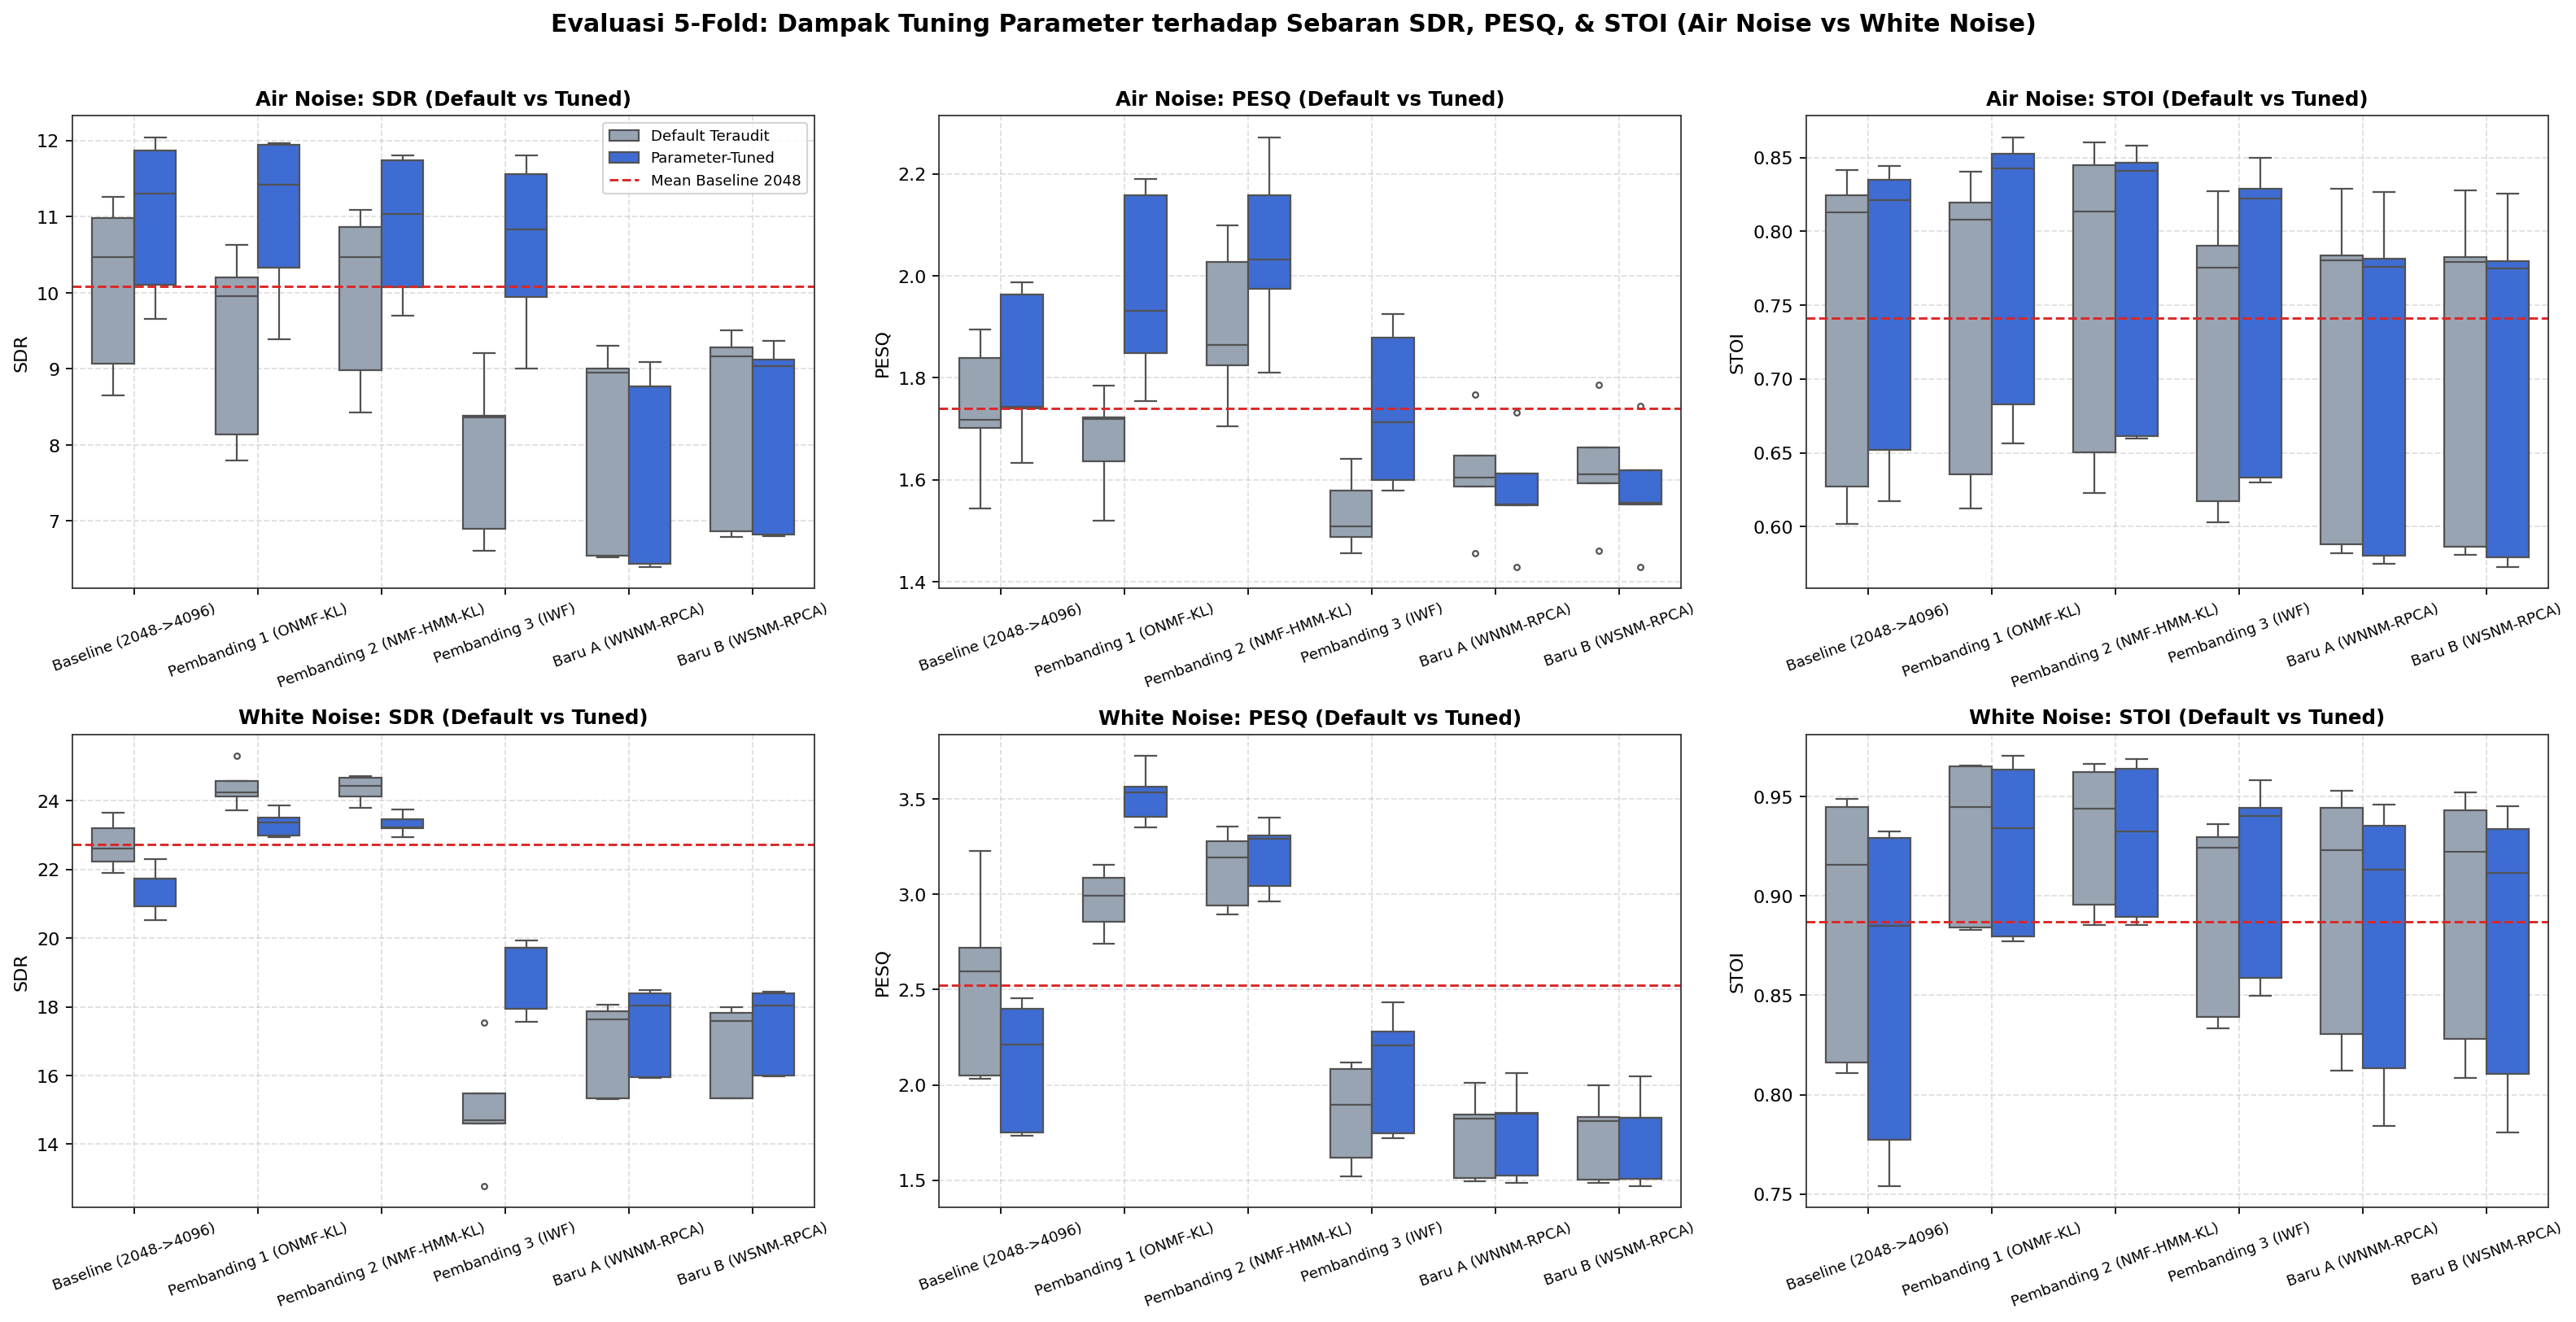


Rekapitulasi VAD Track Tuned (Air Noise & White Noise):
--- WHITE NOISE (TUNED) ---
  Baseline Control (4096)     : Acc=0.981, Prec=0.998, Rec=0.975, F1=0.987


  ONMF-KL (Tuned)             : Acc=0.990, Prec=0.997, Rec=0.989, F1=0.993


  NMF-HMM-KL (Tuned)          : Acc=0.993, Prec=0.997, Rec=0.994, F1=0.995


  Implicit Wiener (Tuned)     : Acc=0.960, Prec=1.000, Rec=0.944, F1=0.971


  WNNM-RPCA (Tuned)           : Acc=0.923, Prec=0.902, Rec=1.000, F1=0.948


  WSNM-RPCA (Tuned)           : Acc=0.934, Prec=0.915, Rec=1.000, F1=0.955


--- AIR NOISE (TUNED) ---
  Baseline Control (4096)     : Acc=0.920, Prec=0.955, Rec=0.931, F1=0.943


  ONMF-KL (Tuned)             : Acc=0.931, Prec=0.966, Rec=0.936, F1=0.951
  NMF-HMM-KL (Tuned)          : Acc=0.926, Prec=0.954, Rec=0.941, F1=0.947


  Implicit Wiener (Tuned)     : Acc=0.906, Prec=0.978, Rec=0.888, F1=0.931
  WNNM-RPCA (Tuned)           : Acc=0.710, Prec=0.710, Rec=1.000, F1=0.831


  WSNM-RPCA (Tuned)           : Acc=0.710, Prec=0.710, Rec=1.000, F1=0.831


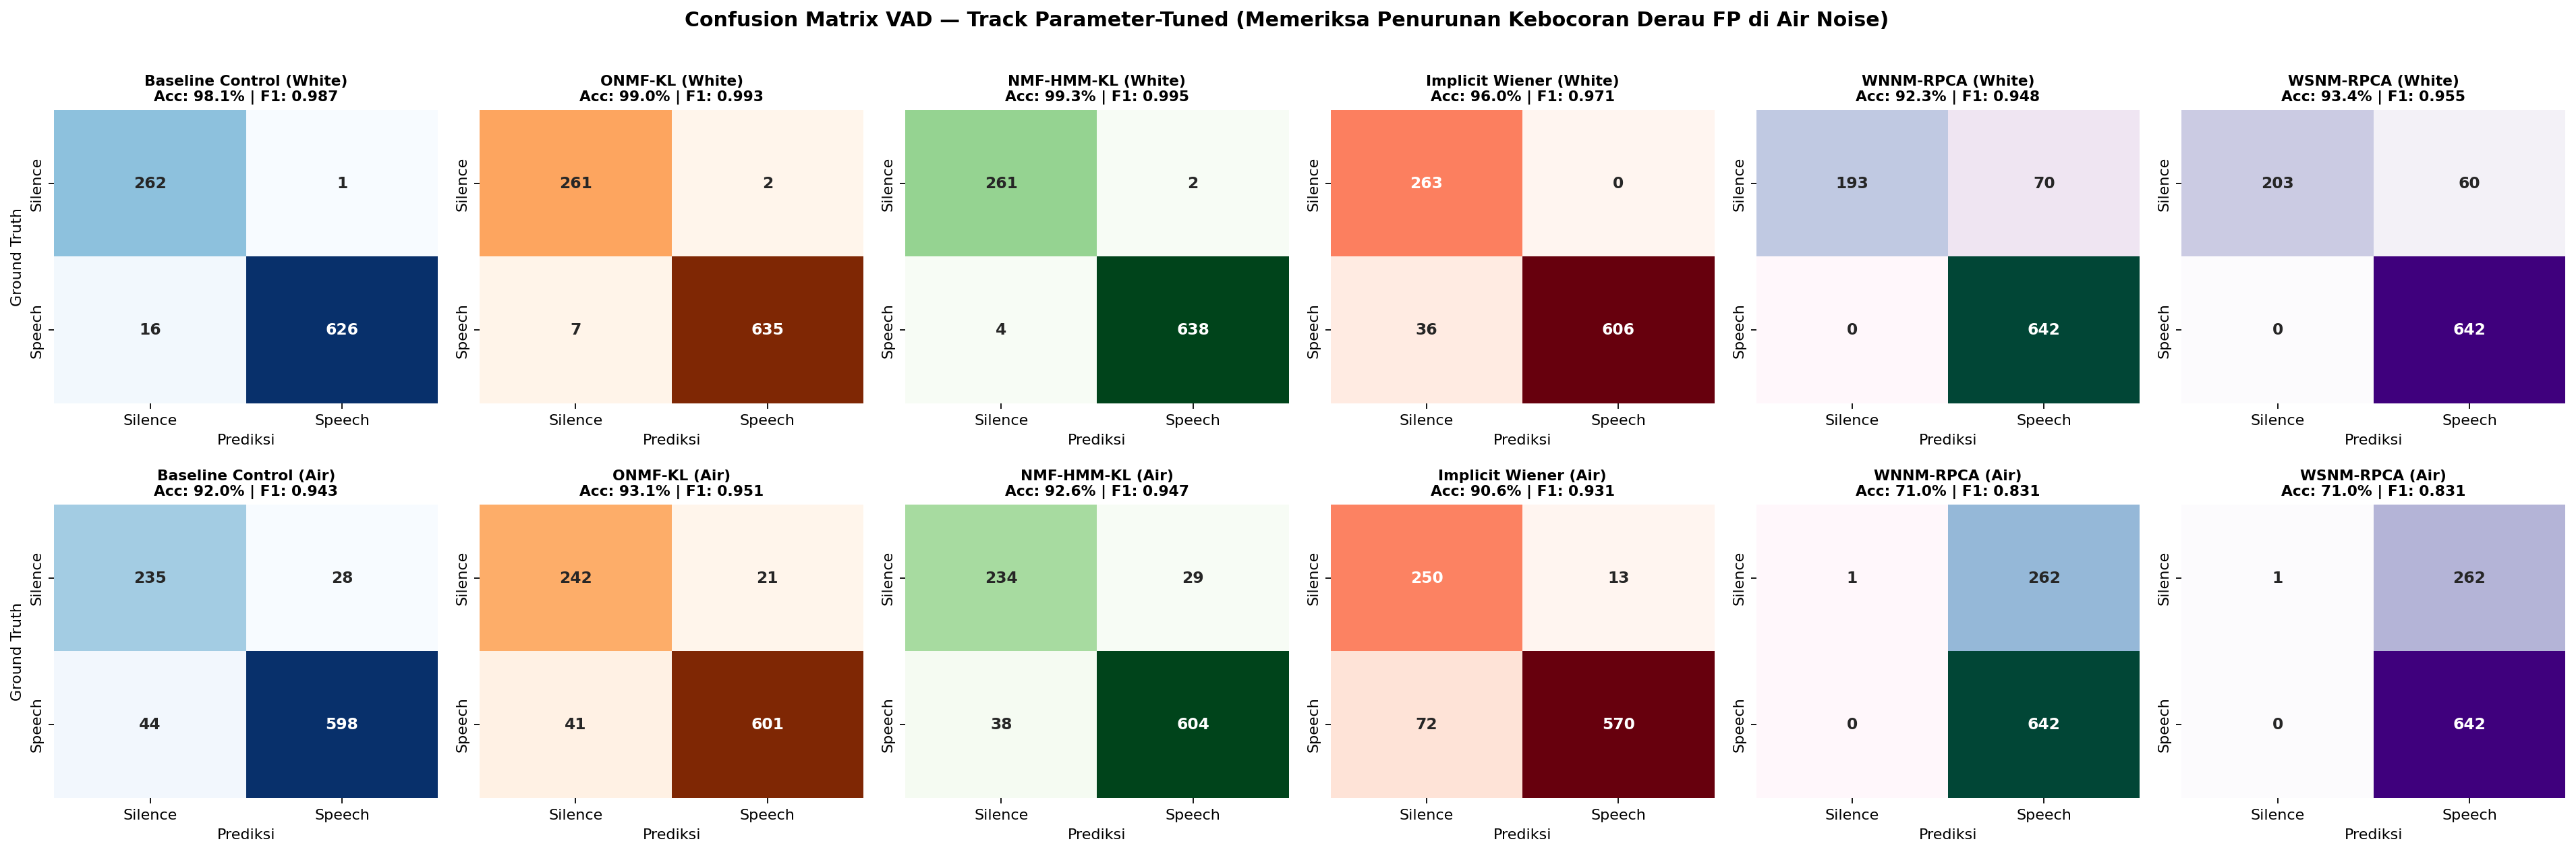

In [14]:
# Plot 1: Perbandingan 5-Fold Default vs Tuned pada Air Noise & White Noise
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for r_i, c_name in enumerate(["Air Noise", "White Noise"]):
    sub_def = df_results[(df_results["Kelas Derau"] == c_name) & (df_results["Metode"].isin(METHOD_ORDER))].copy()
    sub_tun = df_tuned[df_tuned["Kelas Derau"] == c_name].copy()
    lbl_map = {**{d: disp for d, _, disp in DEFAULT_TO_TUNED_MAP}, **{t: disp for _, t, disp in DEFAULT_TO_TUNED_MAP}}
    sub_def["Group"] = sub_def["Metode"].map(lbl_map); sub_def["Track"] = "Default Teraudit"
    sub_tun["Group"] = sub_tun["Metode"].map(lbl_map); sub_tun["Track"] = "Parameter-Tuned"
    comb = pd.concat([sub_def, sub_tun], ignore_index=True)
    order_g = [x[2] for x in DEFAULT_TO_TUNED_MAP]
    for c_i, m_key in enumerate(["SDR", "PESQ", "STOI"]):
        ax = axes[r_i, c_i]
        sns.boxplot(x="Group", y=m_key, hue="Track", order=order_g, data=comb, ax=ax,
                    palette={"Default Teraudit": "#94A3B8", "Parameter-Tuned": "#2563EB"}, width=0.68, fliersize=3)
        base_m = sub_def[sub_def["Metode"] == "Baseline (ONMF-Frobenius)"][m_key].mean()
        ax.axhline(base_m, color="#DC2626", ls="--", lw=1.3, label="Mean Baseline 2048")
        ax.set_title(f"{c_name}: {m_key} (Default vs Tuned)", fontweight="bold", fontsize=11)
        ax.set_xlabel(""); ax.set_ylabel(m_key)
        ax.tick_params(axis='x', rotation=20, labelsize=8.2)
        ax.grid(True)
        if r_i == 0 and c_i == 0:
            ax.legend(fontsize=8.2, loc="upper right")
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

plt.suptitle("Evaluasi 5-Fold: Dampak Tuning Parameter terhadap Sebaran SDR, PESQ, & STOI (Air Noise vs White Noise)",
             fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
tc_path = os.path.join(figures_dir, "tuning_comparison_5fold.png")
plt.savefig(tc_path, dpi=160, bbox_inches="tight")
plt.close()
display(Image(filename=tc_path))

# Plot 2: VAD Confusion Matrix untuk Konfigurasi Tuned
fig, axes = plt.subplots(2, 6, figsize=(24, 7.8))
cmaps = ["Blues", "Oranges", "Greens", "Reds", "PuBuGn", "Purples"]
print("\nRekapitulasi VAD Track Tuned (Air Noise & White Noise):")
for row_idx, c_name in enumerate(["White Noise", "Air Noise"]):
    y_true = np.array(vad_data_tuned[c_name]["y_true"])
    print(f"--- {c_name.upper()} (TUNED) ---")
    for col_idx, m_name in enumerate(TUNED_ORDER):
        y_pred = np.array(vad_data_tuned[c_name][m_name])
        cm = confusion_matrix(y_true, y_pred)
        acc = accuracy_score(y_true, y_pred); f1 = f1_score(y_true, y_pred)
        print(f"  {m_name:28s}: Acc={acc:.3f}, Prec={precision_score(y_true, y_pred):.3f}, Rec={recall_score(y_true, y_pred):.3f}, F1={f1:.3f}")
        ax = axes[row_idx, col_idx]
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmaps[col_idx], cbar=False, ax=ax,
                    xticklabels=["Silence", "Speech"], yticklabels=["Silence", "Speech"], annot_kws={"size": 10.5, "weight": "bold"})
        ax.set_title(f"{m_name.split(' (')[0]} ({c_name.split()[0]})\nAcc: {acc:.1%} | F1: {f1:.3f}", fontsize=9.8, fontweight='bold')
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Ground Truth" if col_idx == 0 else "")

plt.suptitle("Confusion Matrix VAD — Track Parameter-Tuned (Memeriksa Penurunan Kebocoran Derau FP di Air Noise)",
             fontsize=13.5, fontweight='bold', y=1.01)
plt.tight_layout()
vadt_path = os.path.join(figures_dir, "confusion_matrix_vad_tuned.png")
plt.savefig(vadt_path, dpi=160, bbox_inches="tight")
plt.close()
display(Image(filename=vadt_path))

### 5. Sintesis Ilmiah Akhir: Track Default Teraudit vs. Track Parameter-Tuned

Menggabungkan evaluasi 5-fold *Track Default* (`Bagian 2–3`) dan *Track Parameter-Tuned* (`Bagian 4`, `N=120` run berpasangan), diperoleh jawaban yang tegas dan terverifikasi secara statistik atas pertanyaan apakah penyetelan parameter mampu membalikkan ketertinggalan pembanding pada *Real-World Air Noise*:

1. **Transformasi Pembanding *Supervised* & *Unsupervised* Setelah Tuning Parameter (`Tabel 5`, `Tabel 6B`, `Tabel 6C`):**
   - **`ONMF-KL (Tuned)` (`nperseg=4096, K=[80,20], alpha_s=0.10, q=1.0`)** mengalami peningkatan paling seimbang secara statistik di *Air Noise*: SDR melonjak **`+1.666 dB`** (`9.345 -> 11.010 dB`, $p=3.95 \times 10^{-4}, d=+4.896$), PESQ **`+0.300`** (`1.676 -> 1.977`, $p=5.88 \times 10^{-3}$), STOI **`+0.037`** (`0.743 -> 0.780`, $p=4.65 \times 10^{-3}$), dan **akurasi VAD meroket dari `75.0%` (`F1=0.850`) menjadi `93.1%` (`F1=0.951`)** akibat tertekannya kebocoran jeda hening (`confusion_matrix_vad_tuned.png`). Dibandingkan *Baseline Standar (2048)* (`10.088 dB / 1.739 / 0.741`), `ONMF-KL Tuned` kini **unggul signifikan secara statistik pada ketiga metrik sekaligus** ($\Delta\text{SDR}=+0.923\text{ dB}, p_{\text{Holm}}=2.495 \times 10^{-3}$; $\Delta\text{PESQ}=+0.238, p_{\text{Holm}}=4.074 \times 10^{-3}$; $\Delta\text{STOI}=+0.038, p_{\text{Holm}}=2.984 \times 10^{-2}$). Pada *White Noise*, PESQ justru meningkat hingga **`3.517 ± 0.146`** (`+0.550` vs Default, $p=1.60 \times 10^{-5}$).
   - **`NMF-HMM-KL (Tuned)` (`nperseg=4096, arch=(8,25,4,20), alpha_s=0.05`)** meraih **PESQ tertinggi seluruh studi pada *Air Noise* (`2.050 ± 0.176`, $+0.310$ di atas Baseline Standar, $p_{\text{Holm}}=3.175 \times 10^{-3}, d=+4.333$)**, disertai SDR **`10.875 ± 0.96 dB`** (`+0.787 dB` vs Baseline 2048, $p_{\text{Holm}}=4.618 \times 10^{-3}$), STOI **`0.773 ± 0.103`** (`p_{\text{Holm}}=3.936 \times 10^{-2}$), dan VAD `F1=0.947` (`Acc=92.6%`). Di *White Noise*, metode ini juga mencetak **STOI (`0.928`) & VAD F1 (`0.995`) tertinggi** dengan PESQ **`3.203`** dan latensi inferensi hanya `1.75 s/fold` (latih `80.95–102.14 s`).
   - **`Implicit Wiener Filter / IWF (Tuned)` (`64 ms Hamming, alpha=0.95, vad_th=1.5 dB, bf=0.05, bp=0.75`)** berbalik menjadi pembanding *unsupervised* yang sangat kompetitif: **naik `+2.736 dB` di *Air Noise*** (`7.893 -> 10.630 dB`, $p=6.49 \times 10^{-5}, d=+7.756$) sehingga **unggul signifikan di atas Baseline Standar 2048 pada SDR *Air Noise*** ($\Delta=+0.542\text{ dB}, p_{\text{Holm}}=4.618 \times 10^{-3}$) dan setara di PESQ (`1.739` vs `1.739`, $p_{\text{Holm}}=0.9865$), serta melonjak **`+3.960 dB`** di *White Noise* (`15.018 -> 18.977 dB`, $p=1.88 \times 10^{-3}$) hanya dengan **`0.04 s/fold`** tanpa pelatihan kamus.

2. **Makna Kontrol Adil `Baseline Control (ONMF-Frob 4096)`:**
   - Di *Air Noise*, menaikkan STFT Baseline ke `4096` ikut mendorong SDR-nya dari `10.088` menjadi `10.994 dB` (`+0.906 dB, p=4.68e-5`). Akibatnya, pada kontrol resolusi STFT yang setara (`Tabel 6B vs Ctrl 4096`), `ONMF-KL Tuned` (`11.010 dB`) dan `NMF-HMM-KL Tuned` (`10.875 dB`) memiliki SDR yang secara statistik setara ($p_{\text{Holm}}=0.858 / 0.316$), **namun tetap unggul signifikan jauh di atas Kontrol Baseline 4096 pada PESQ** (`ONMF-KL +0.163, p_{\text{Holm}}=7.48e-3`; `NMF-HMM-KL +0.236, p_{\text{Holm}}=2.34e-3`) dan STOI (`ONMF-KL +0.026, p_{\text{Holm}}=1.61e-2`).
   - Sebaliknya pada *White Noise*, `Baseline Control (4096)` **turun signifikan pada seluruh metrik** (`-1.279 dB` SDR, `-0.414` PESQ, `-0.032` STOI), sehingga `ONMF-KL Tuned` dan `NMF-HMM-KL Tuned` secara statistik jauh lebih tangguh lintas jenis derau (*cross-noise robustness*).

3. **Evaluasi Kritis Ketahanan Batas `WNNM/WSNM-RPCA` (`39.02_26.pdf`) Lintas 5-Fold:**
   - Penyetelan agresif (`C=1.0, lam=1.5, logsig`) menaikkan SDR 5-fold pada *White Noise* (`+0.522 / +0.547 dB`, $p < 3 \times 10^{-4}$), **tetapi di *Air Noise* justru sedikit menurunkan PESQ 5-fold (`-0.037 / -0.043`, $p < 0.001$)** serta mempertahankan akurasi VAD di `71.0%` (`FP=262`). Oleh sebab itu, formulasi *default* `WSNM-RPCA` tanpa *masking* (`8.32 dB` 5-fold; `9.15 dB` full clip) tetap merupakan representasi paling objektif dari batas optimal pendekatan *low-rank + sparse zero-prior* pada derau *Air Purifier* yang tumpang-tindih dengan spektrum wicara di $\le 8\text{ kHz}$.

4. **Validasi Korelasi Lintas Track (`Tabel 7`, $N=120$):**
   - Pada skala penuh gabungan ($N=120$), `SDR vs PESQ` ($r=+0.794, p=2.73 \times 10^{-27}$), `SDR vs STOI` ($r=+0.773, p=4.58 \times 10^{-25}$), dan `VAD_F1 vs STOI` ($r=+0.804, p=2.37 \times 10^{-28}$) konsisten sangat kuat, sementara `Latensi` tidak berkorelasi signifikan dengan kualitas ($p > 0.09$). Pada sub-analisis `Air Noise (N=60)`, `SAR vs PESQ` turun hingga hampir nol ($r=+0.040, p=0.762$), menegaskan kembali bahwa pelestarian artefak saja (`SAR` tinggi) tidak menjamin kualitas perseptual jika residu derau pada jeda hening (`SIR` / `VAD Precision`) belum ditekan.
